In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi



In [3]:
prefix = '/mnt/staging/'
mouse='cm128'

step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'
face_h5_root = step_3_root+mouse+'/dlc_face_h5s/'
pupil_root = step_3_root

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"


save_path = str(PREPARES / "heterogeneity") + "/"


# 1. spontaneous running

In [4]:
# files without random stim

f1 = [f for f in glob.glob(step_1_root + "*128/[1-3]/*[B-J]*.mat", recursive=True)] # runB rotary bug

file_spont = f1
file_spont

['/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/2/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/2/runH_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/2/runE_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/2/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/2/runF_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/2/runI_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/2/runJ_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/2/runB_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/2/runG_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/3/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm128/3/runH_stim_1.mat',
 '/mnt/staging/users/wx2203/data

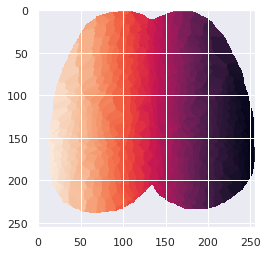

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
plt.imshow(IDX_sorted)

In [6]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

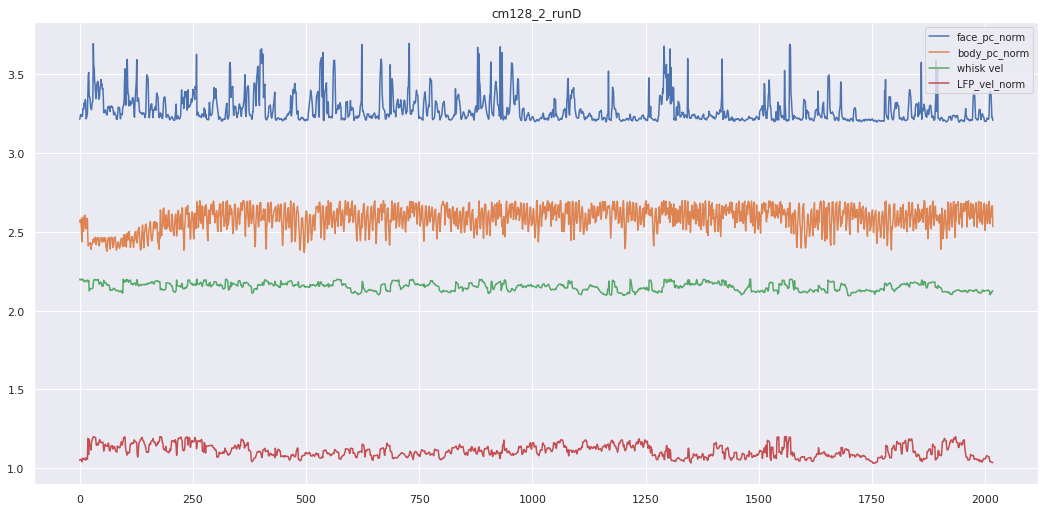

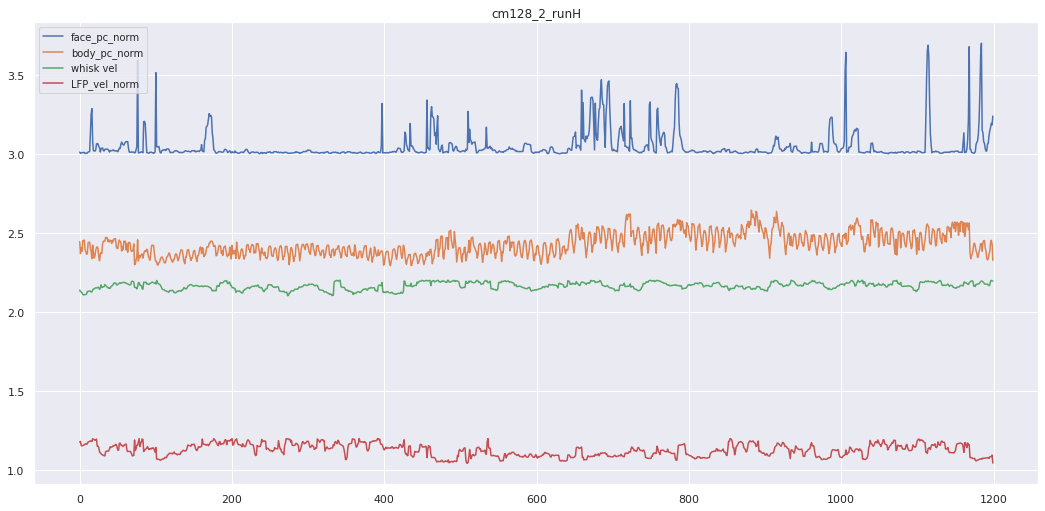

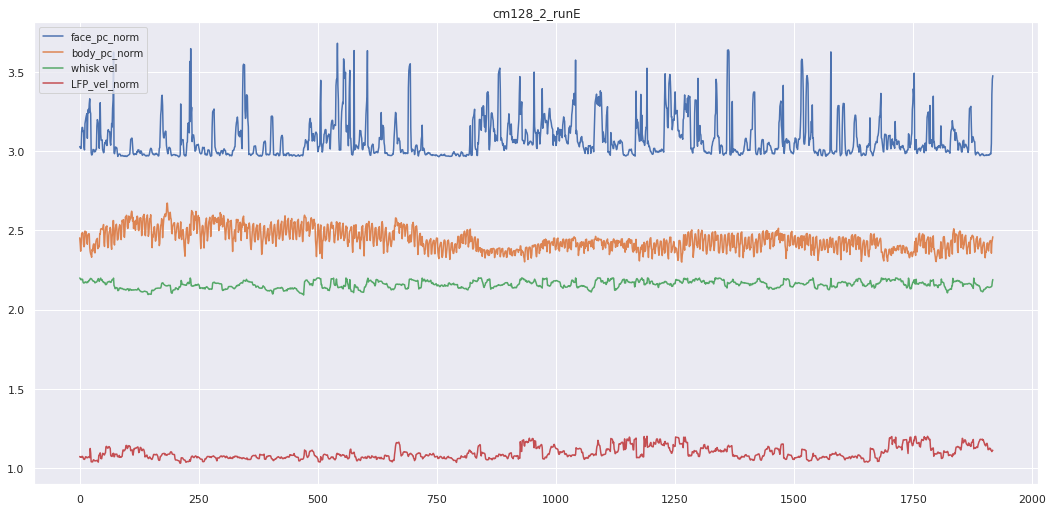

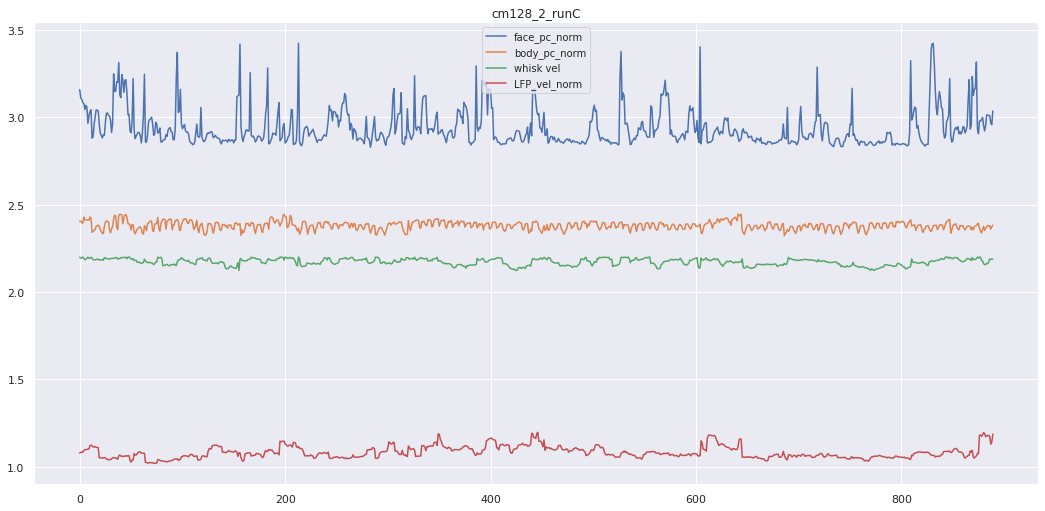

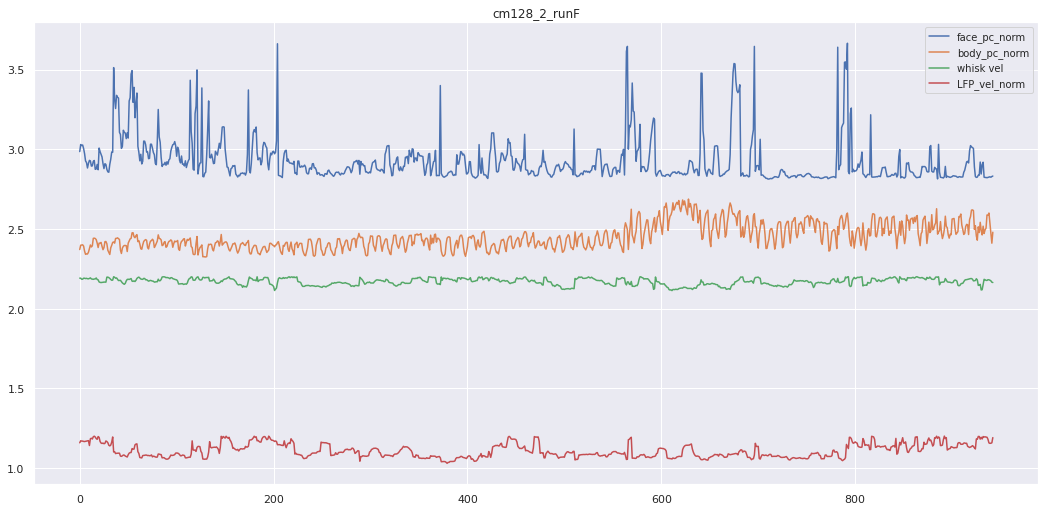

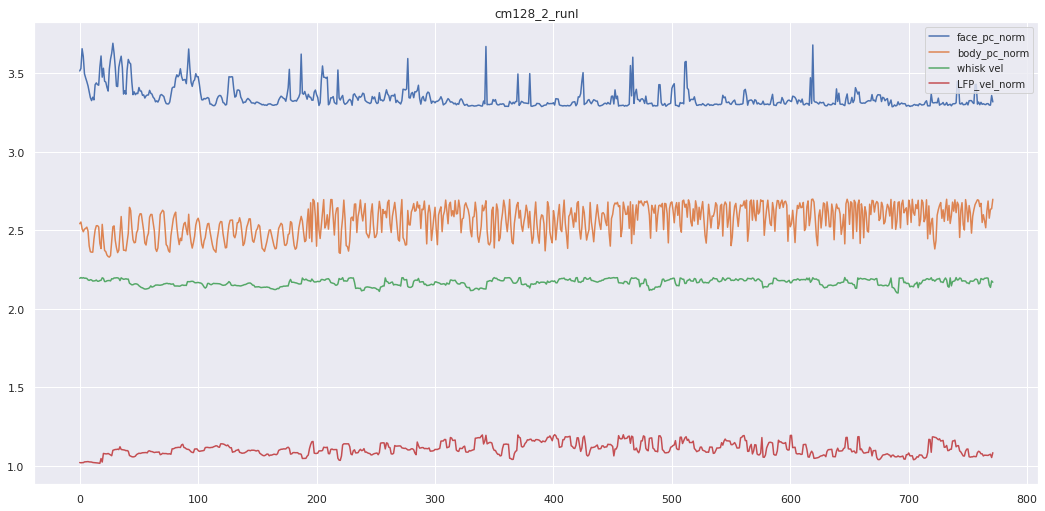

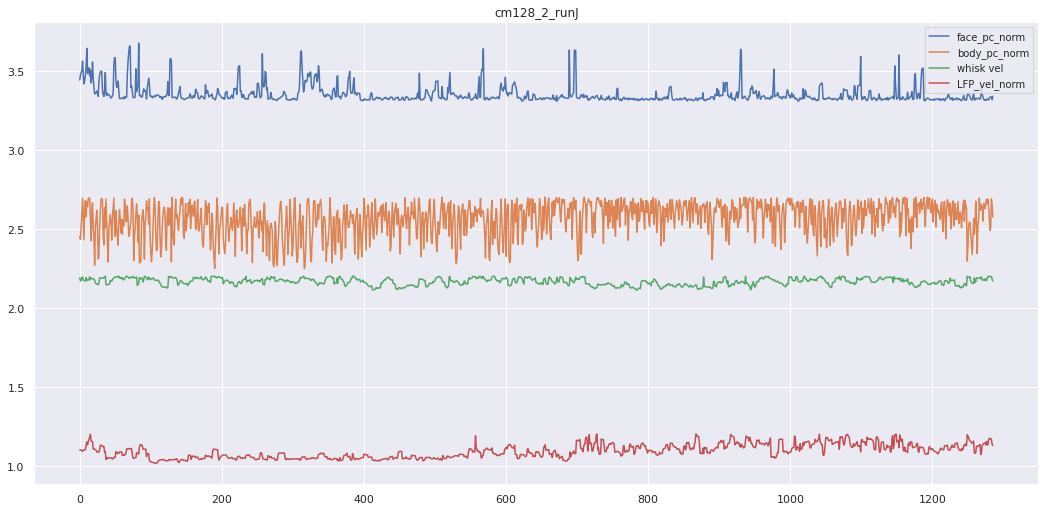

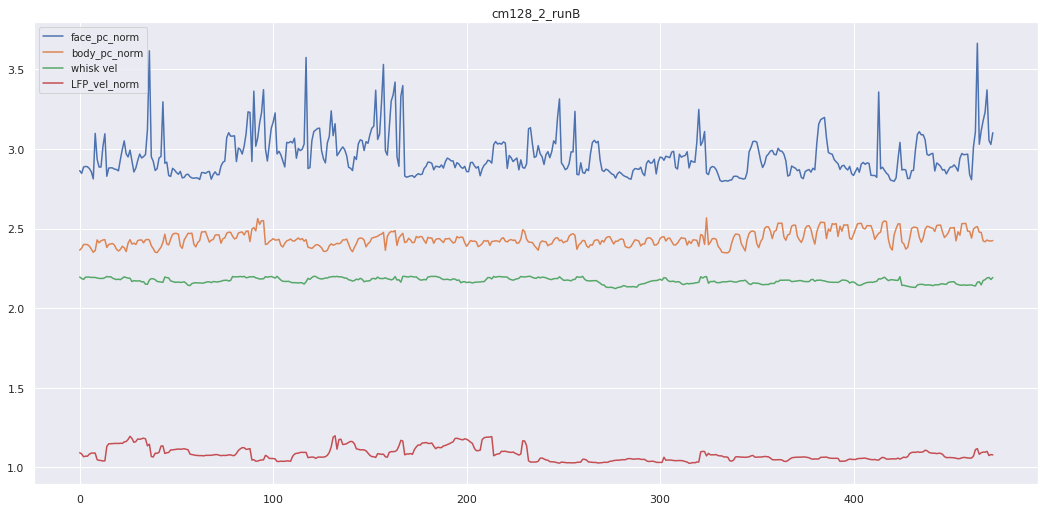

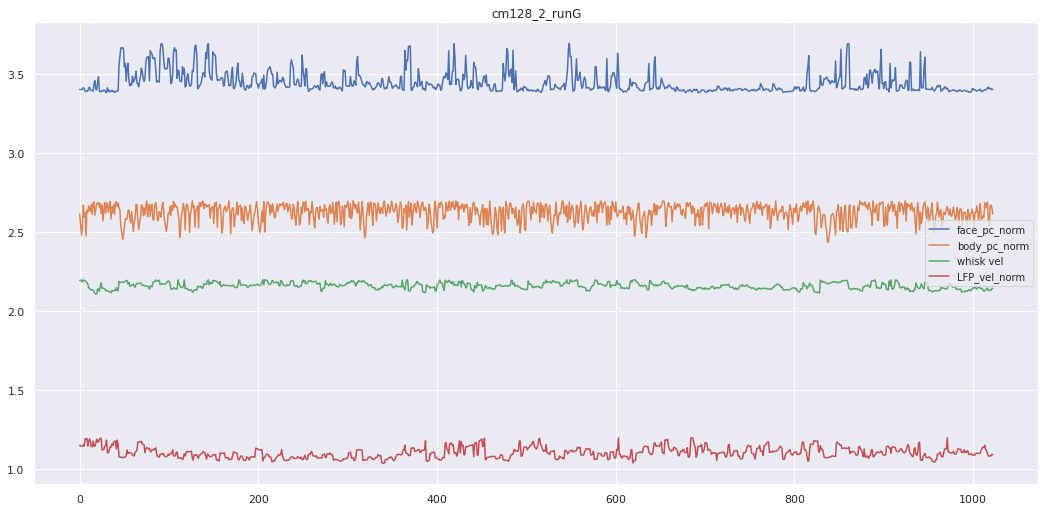

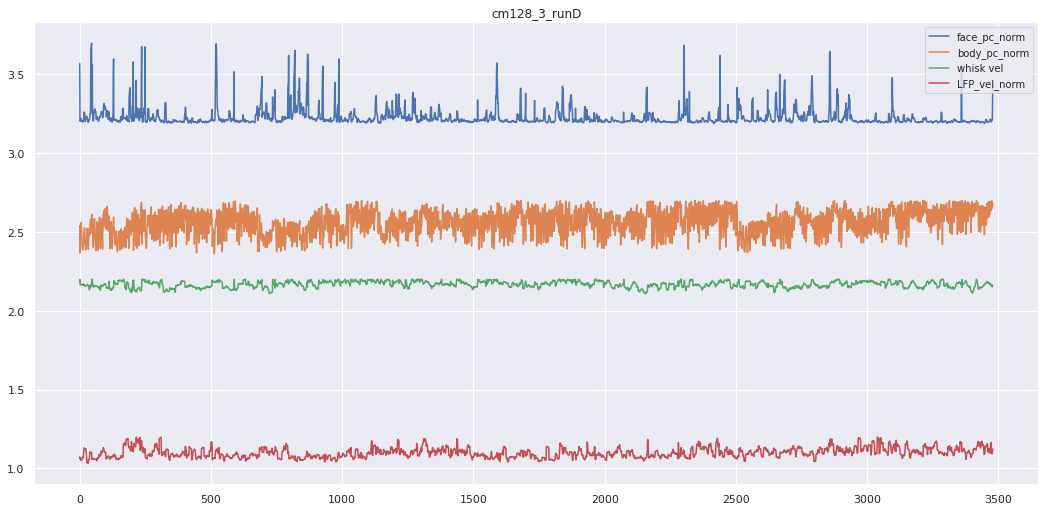

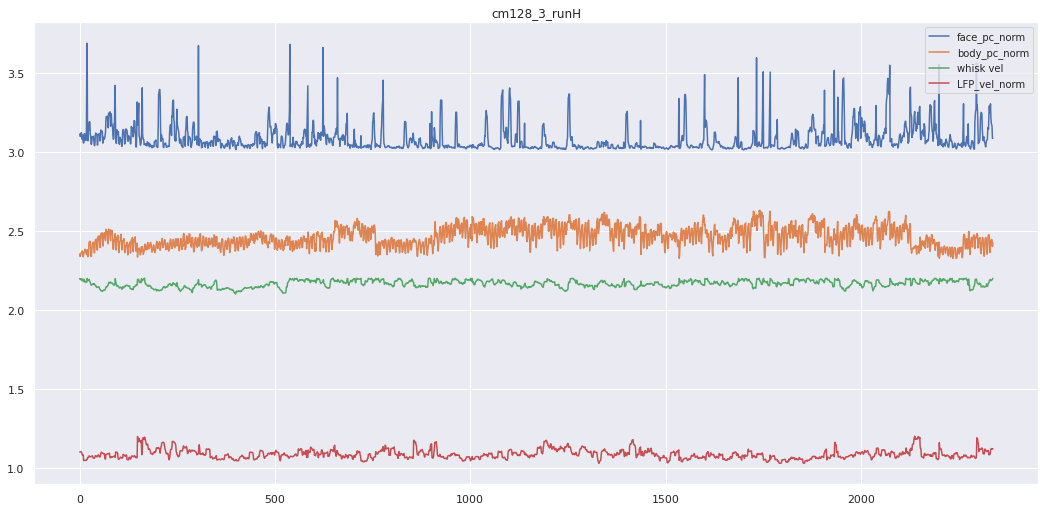

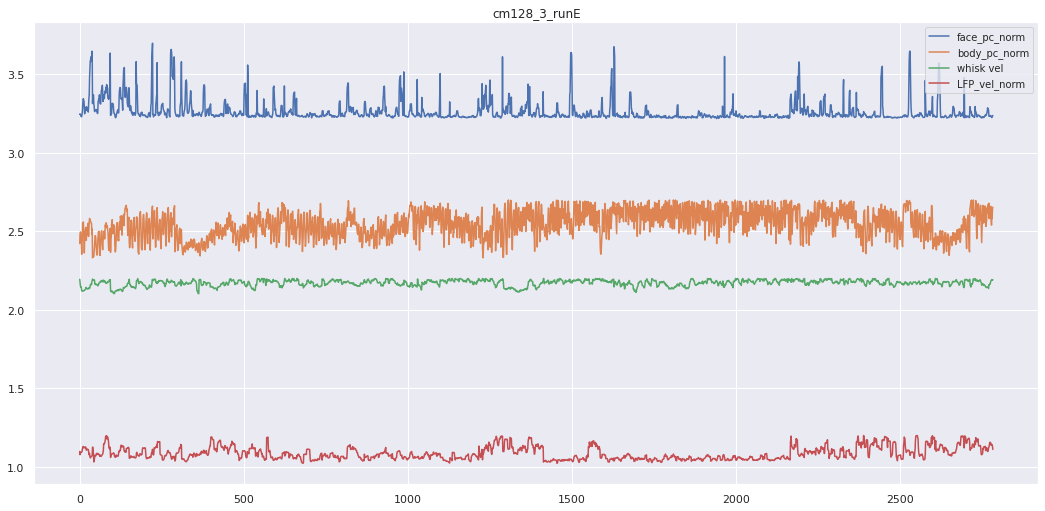

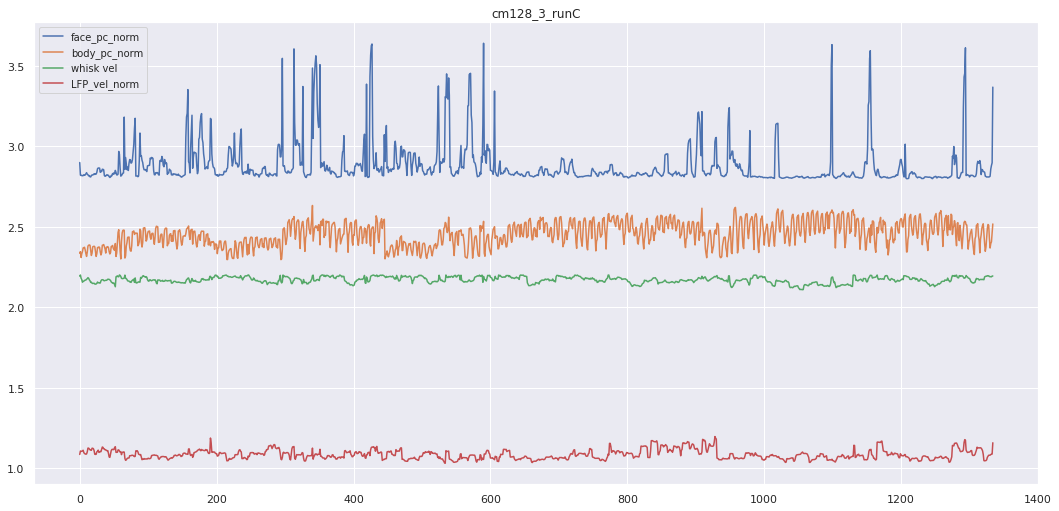

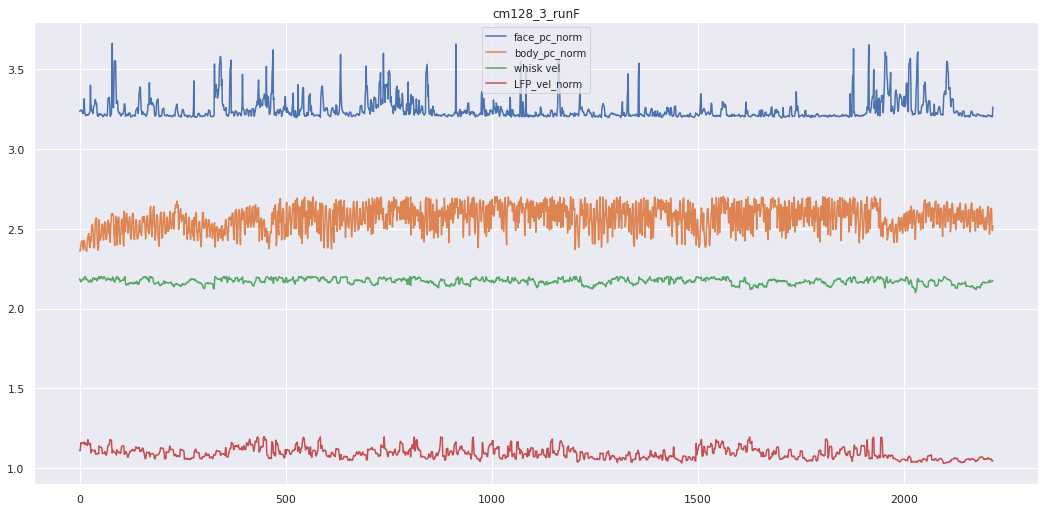

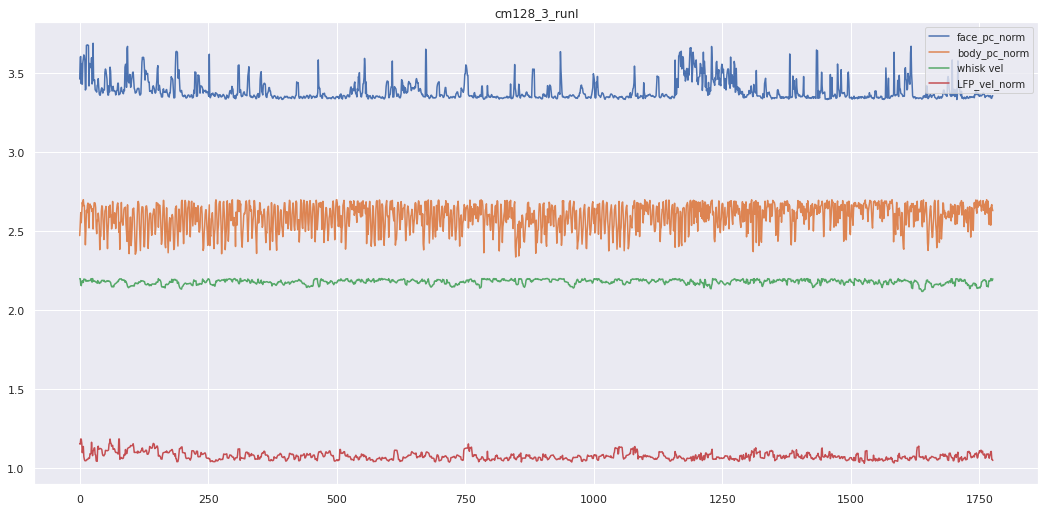

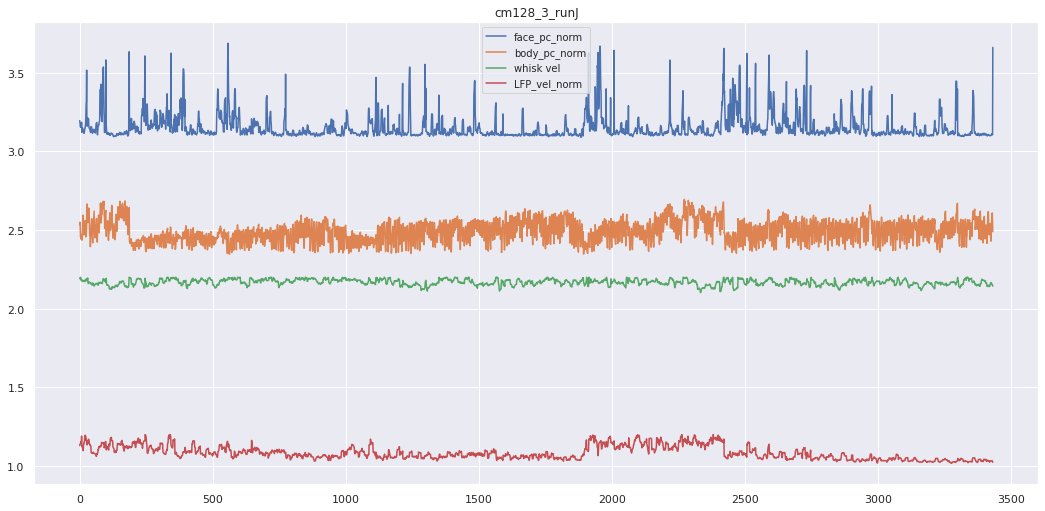

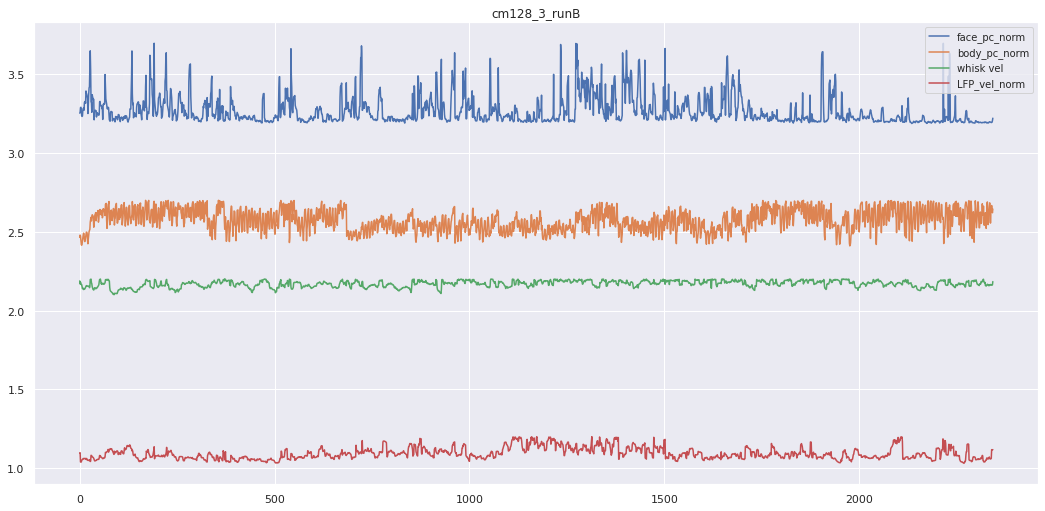

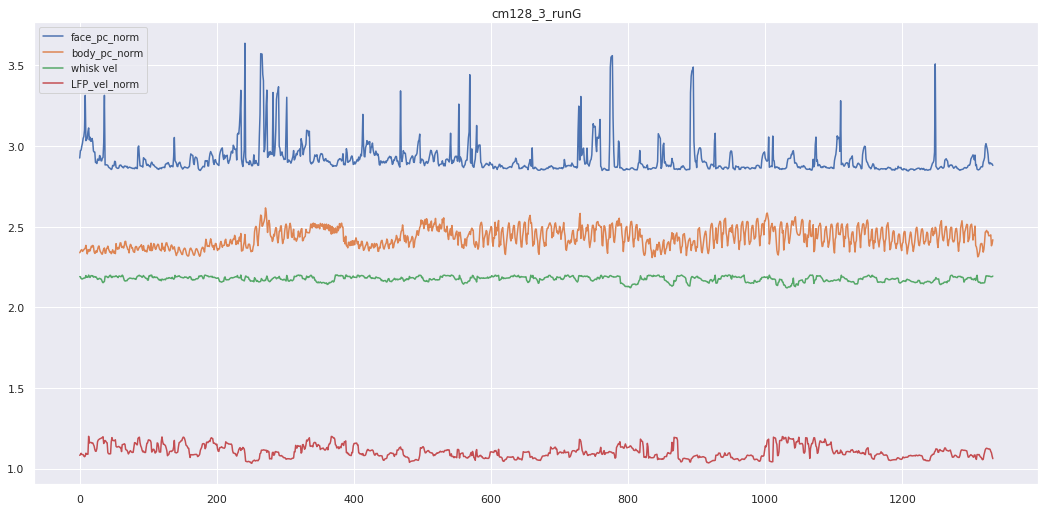

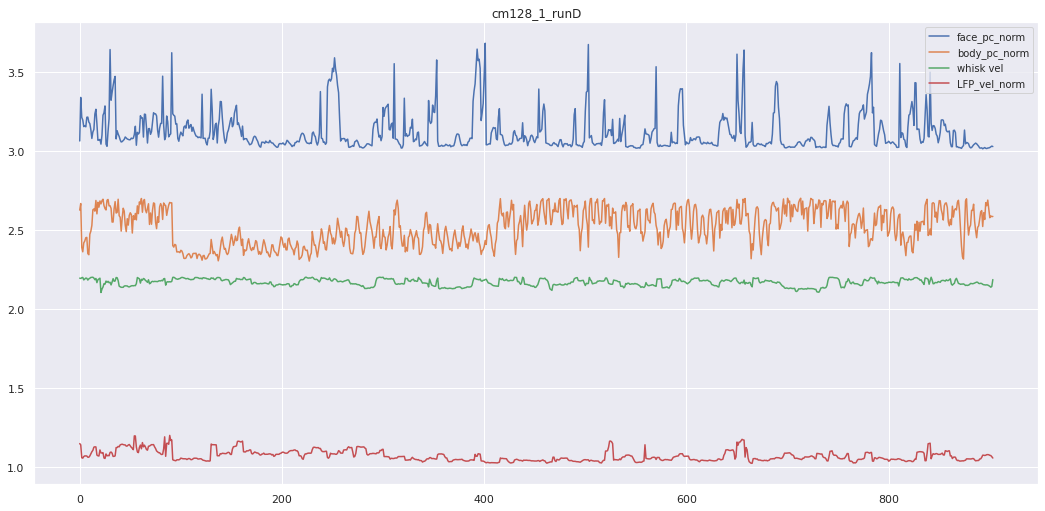

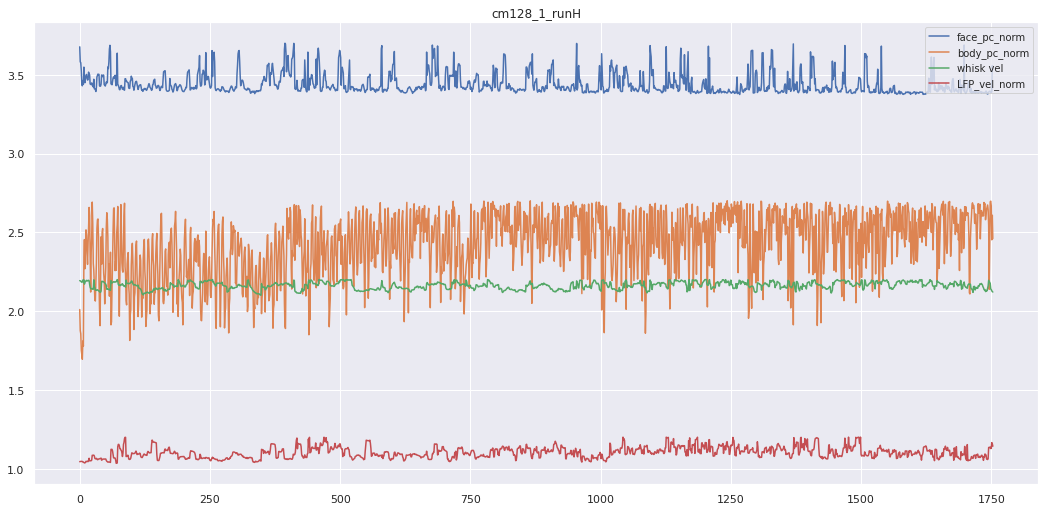

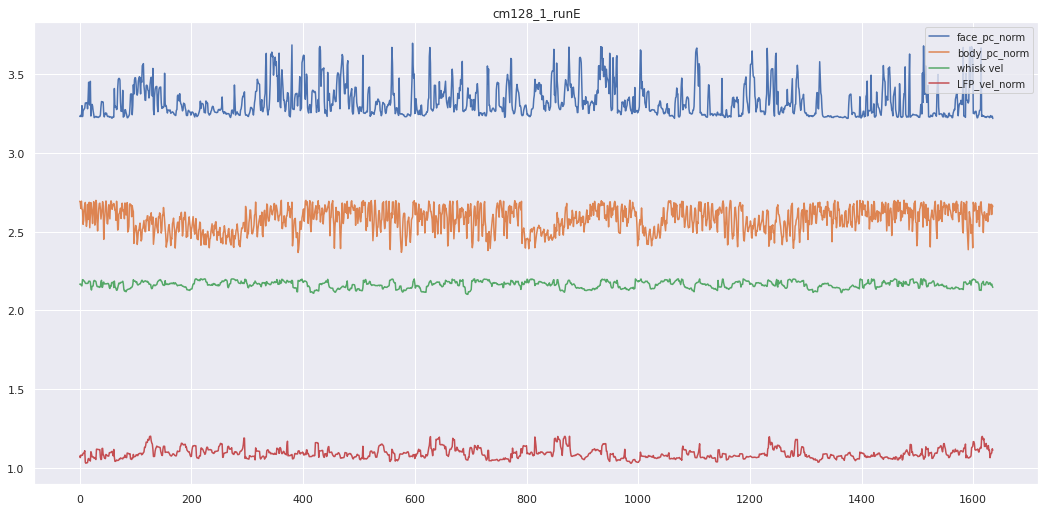

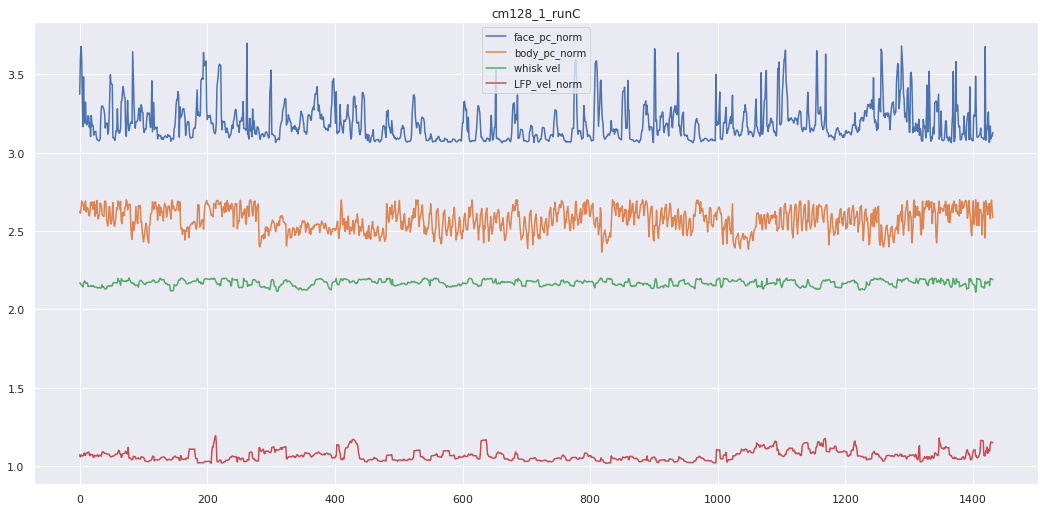

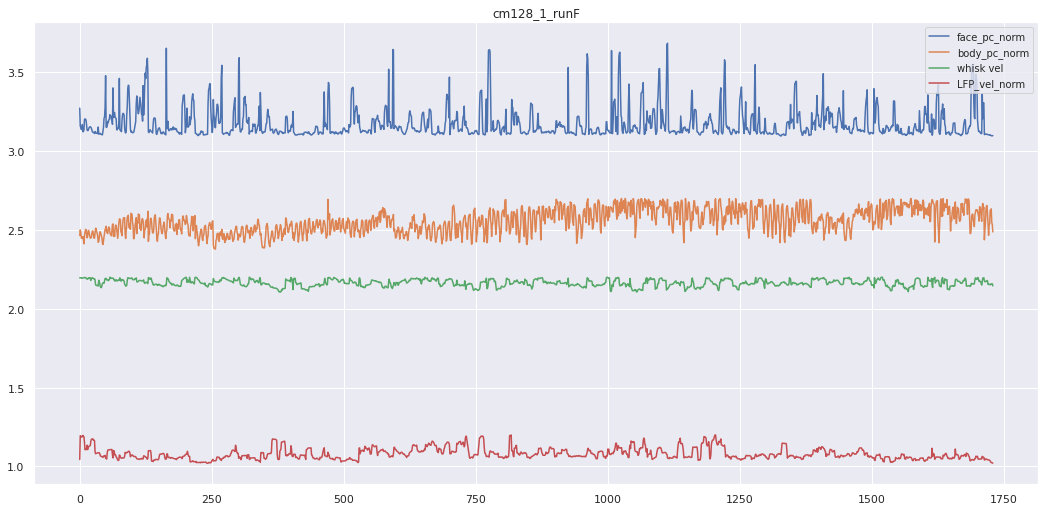

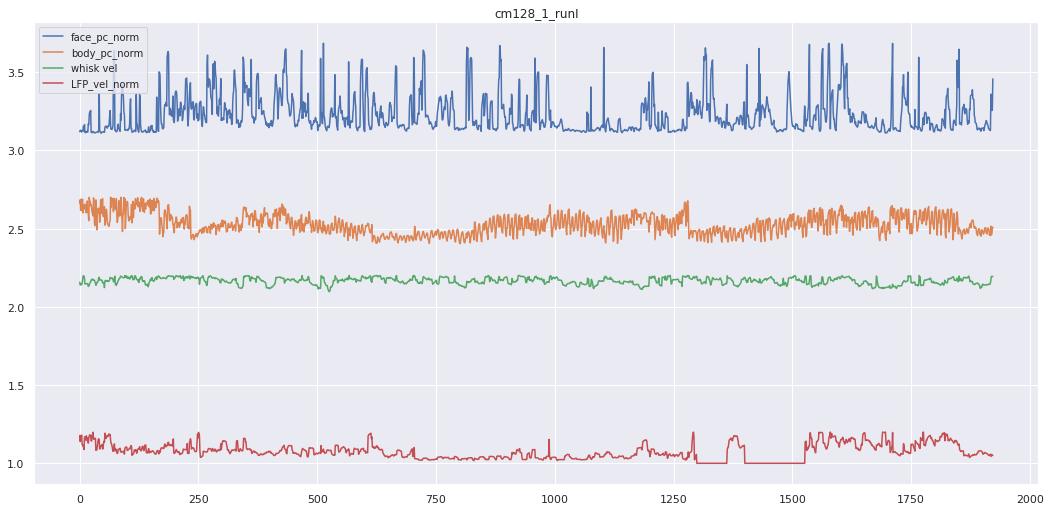

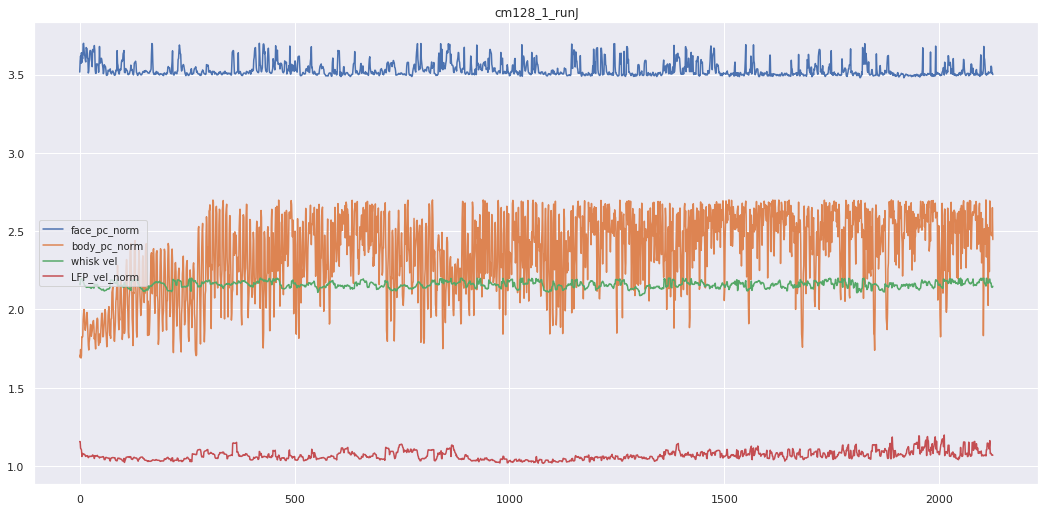

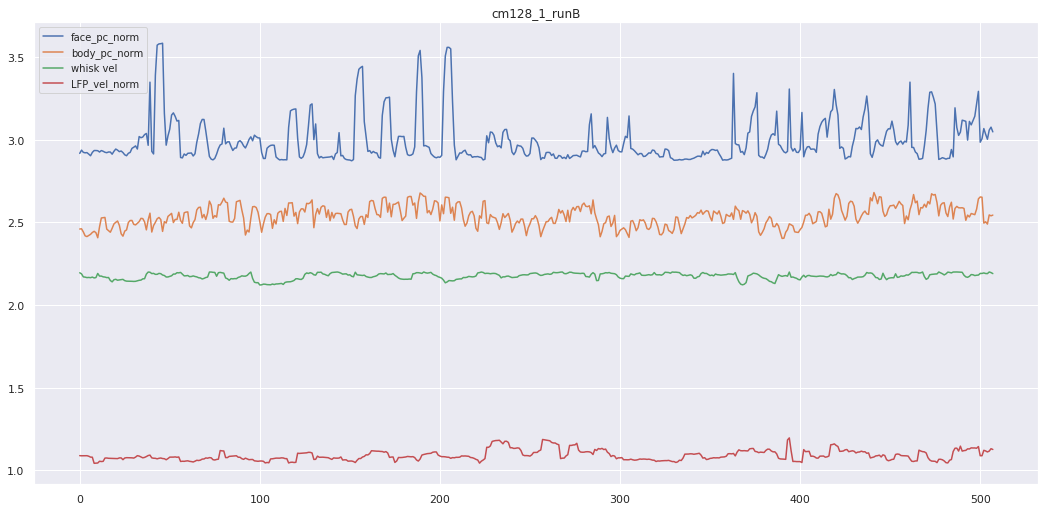

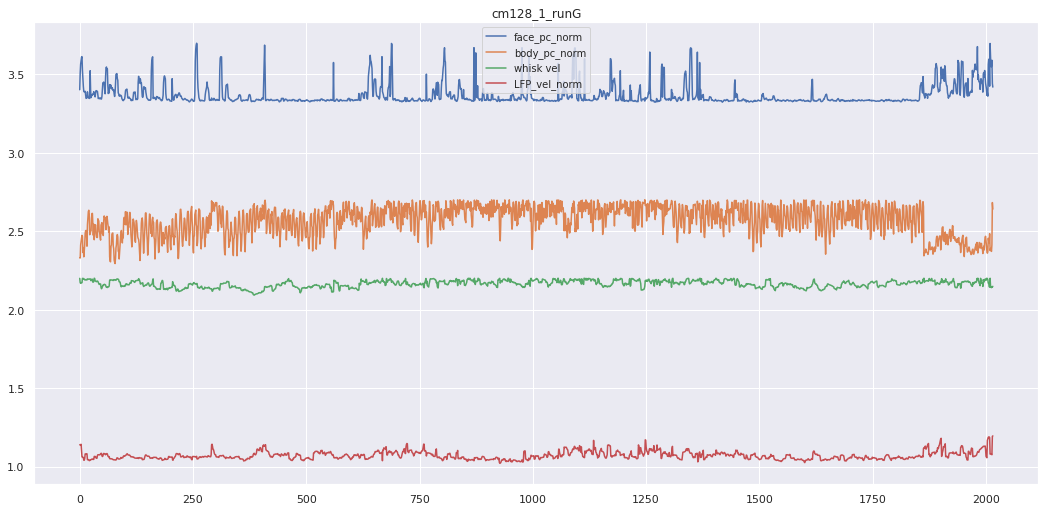

In [7]:
sns.set()
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

M_jrgeco = np.empty((256,256,0))
M_whisk_vel_norm = np.empty((0))
M_LFP_vel_norm = np.empty((0))
M_body_pc_norm = np.empty((0))
M_face_pc_norm = np.empty((0))

for i_file,fname in enumerate(file_spont): 
    run_name = fname.split('_stim_1')[0][-4:]
    mouse = fname.split('step_1/')[1][:5]
    day = fname.split('step_1/')[1][6:7]
    mouse_day = mouse+'_'+day
    run=run_name

    try:
        f_jrgeco = h5py.File(fname,'r')
        C = np.array(f_jrgeco['C']['jrgeco'])
        S = np.array(f_jrgeco['S']['jrgeco'])
        m = f_jrgeco['m']
        nanidx = np.squeeze(m['nanidx'])
        CS = np.dot(S,C).transpose()
        jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
        jrgeco[:] = np.nan
        jrgeco[nanidx==1,:] = CS
        jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))

        jrgeco = jrgeco[:,:,500:-500]
    except:
        print('missing',mouse,day,'H_'+run+'_stim_1.mat')
        continue
        
   
    ################################### whisking velocity (11980,)
    try:
        f_name_dlc = glob.glob(face_h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        prominent_whiskers=bodyparts[7:] #plot most prominent whiskers

        vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(prominent_whiskers):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel_df[bpt] = vel
        mean_vel = vel_df.mean(axis=1)
        smooth_mean_vel = mean_vel.rolling(60).std()
        smooth_mean_vel_ds = np.mean(smooth_mean_vel[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        whisk_vel = smooth_mean_vel_ds[500:-505]
        #
        nose_pts=bodyparts[:7]
        nose_vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(nose_pts):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            nose_vel_df[bpt] = vel
        mean_nose_vel = nose_vel_df.mean(axis=1)
        smooth_mean_nose_vel = mean_nose_vel.rolling(60).std() # smooth
        smooth_mean_nose_vel_ds = np.mean(smooth_mean_nose_vel[:-1].values.reshape((-1,3)),axis=1)
        nose_vel = smooth_mean_nose_vel_ds[500:-505]

    except:
        print('whisking velocity missing ',mouse_day+'_'+run)
        continue
        
    try:
        with(h5py.File(pjoin(step_3_root,mouse,
                             day,run+'_cam_pc.mat'),'r')) as f_b:
            motionS = f_b['motionS']# this is the HDF5 reference
            motion_pc = {key: [] for key in list(motionS.keys())} 
            for key in list(motionS.keys()):
                motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
                motion_pc[key]= motion_pc[key].iloc[:,:-5]
                
                motion_pc[key] = motion_pc[key].rolling(window=5,axis=1).std()
                motion_pc[key]=motion_pc[key].iloc[:,500:-500]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

    except:
        
        continue

        
    # try:    


    f_name_dlc = glob.glob(h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
    new_df = Dataframe[scorer] # de-level

    paws_vel_df = pd.DataFrame()
    bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
    for i_bpt,bpt in enumerate(bodyparts):

        p_value = new_df[bpt]['likelihood']
        new_df[bpt]['x'][p_value<0.1]=np.nan
        new_df[bpt]['y'][p_value<0.1]=np.nan
        new_df[bpt] = new_df[bpt].interpolate()
        new_df[bpt] = new_df[bpt].fillna(0) # in case nan in first few rows

        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
        vel = pd.DataFrame(vel).rolling(30).std()
        vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
        paws_vel_df[bpt] = vel[500:-505]
    LFP_vel = np.array(paws_vel_df['LFP'])
    RFP_vel = np.array(paws_vel_df['RFP'])



#     except:
#         print('grooming missing ',mouse_day+'_'+run)   
#         continue
             
        
    
    face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
    face_pc = stats.zscore(np.array(face_pc))
    body_pc = motion_pc['body'].iloc[:200,:].mean(axis=0)
    body_pc = stats.zscore(np.array(body_pc) )   
    whisk_vel_norm = whisk_vel
    nose_vel_norm = nose_vel
    LFP_vel_norm = LFP_vel
    RFP_vel_norm = RFP_vel
    

    
    
    # NOW remove movement
    try:
        is_body_move = body_pc>-0.3
        is_face_move = face_pc>-0.3
        is_still = np.logical_and(~is_body_move,~is_face_move)

        whisk_vel_norm = whisk_vel_norm[is_still]
        LFP_vel_norm = LFP_vel_norm[is_still]
        jrgeco = jrgeco[:,:,:len(is_still)]
        face_pc_norm = face_pc[is_still]
        body_pc_norm = body_pc[is_still]

        # Second filt
        is_whisk_move = whisk_vel_norm>0.2
        is_LFP_move = LFP_vel_norm>0.2
        is_still = np.logical_and(~is_LFP_move,~is_whisk_move)

        whisk_vel_norm = whisk_vel_norm[is_still]
        LFP_vel_norm = LFP_vel_norm[is_still]
        jrgeco = jrgeco[:,:,:len(is_still)]
        face_pc_norm = face_pc_norm[is_still]
        body_pc_norm = body_pc_norm[is_still]
    except:
        print('cannot cancat: ',mouse,day,run)
        continue    
    
    try:
        plt.figure(figsize=(18,8.5))
        
        plt.plot(face_pc_norm+4,label='face_pc_norm')
        plt.plot(body_pc_norm+3,label='body_pc_norm')
        plt.plot(whisk_vel_norm+2,label='whisk vel')
        plt.plot(LFP_vel_norm+1,label='LFP_vel_norm')
        plt.title(mouse_day+'_'+run_name)
#         plt.plot(H[134,:]*8-0.5,label='geco paw region')
#         plt.plot(H[143,:]*8-1.5,label='geco front region')
        plt.legend(fontsize = 10)
    except:
        print('no start_stop_ind')
        continue

    M_jrgeco = np.append(M_jrgeco,jrgeco,axis=2)
    M_whisk_vel_norm = np.append(M_whisk_vel_norm,whisk_vel_norm,axis=0)
    M_LFP_vel_norm = np.append(M_LFP_vel_norm,LFP_vel_norm,axis=0)
    M_face_pc_norm = np.append(M_face_pc_norm,face_pc_norm,axis=0)
    M_body_pc_norm = np.append(M_body_pc_norm,body_pc_norm,axis=0)



In [8]:
H_jrgeco = getH(M_jrgeco,IDX_sorted)

In [10]:
# Write  # FULL (256,256, time)
# all_gathered = ['M_jrgeco','M_whisk_vel_norm','M_LFP_vel_norm','M_body_pc_norm','M_face_pc_norm']
# all_gathered_dict = {key:[] for key in all_gathered}
# for key in all_gathered_dict:
#     exec("all_gathered_dict[key] = {}".format(key))
# # ginormous
# with h5py.File(save_path+mouse+'_all_concat_full', 'w') as h5file:
#     for key, item in all_gathered_dict.items():
#         h5file[key] = item
        
        
# Write  # 500 regions (500, time)
all_gathered = ['H_jrgeco','M_whisk_vel_norm','M_LFP_vel_norm','M_body_pc_norm','M_face_pc_norm']
all_gathered_dict = {key:[] for key in all_gathered}
for key in all_gathered_dict:
    exec("all_gathered_dict[key] = {}".format(key))
    
with h5py.File(save_path+mouse+'_all_concat_500_regions', 'w') as h5file:
    for key, item in all_gathered_dict.items():
        h5file[key] = item

In [11]:
H_jrgeco.shape

(500, 133062)

In [12]:
# Read
mouse='cm128'
file = h5py.File(save_path+mouse+'_all_concat_full', 'r')
keys = file.keys()
# all_gathered_dict = {}
for key in keys:
    exec("{} = file[key][()]".format(key))

In [ ]:
M_jrgeco.shape

In [ ]:
boolean = M_LFP_vel_norm<0.07
rest_ind = np.where(boolean==True)[0]
rest_ind.shape

In [ ]:
M_jrgeco=M_jrgeco[:,:,rest_ind]

In [37]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)
def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
def set_level_values(midx, level, values):
    full_levels = list(zip(*midx.values))
    names = midx.names
    if isinstance(level, str):
        if level not in names:
            raise ValueError(f'No level {level} in MultiIndex')
        level = names.index(level)
    if len(full_levels[level]) != len(values):
        raise ValueError('Values must be of the same size as original level')
    full_levels[level] = values
    return pd.MultiIndex.from_arrays(full_levels, names=names)

def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))

    if if_return_map ==True:
        return std_map
    else:
        plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
        plt.axis('off')
        plt.colorbar()


In [38]:
def get_corr_map_full(M_jrgeco,region_number):
    
    ind_boolean = np.zeros(500);ind_boolean[:] = np.nan
    ind_boolean[region_number] = 1
    ind_map = show_map(ind_boolean,caxis=[0,1],if_return_map=True)
    seed_H = np.nanmean(np.nanmean(np.multiply(np.repeat(ind_map[:,:,np.newaxis],repeats=M_jrgeco.shape[-1],axis=2),M_jrgeco),axis=0),axis=0)
    
    ss=M_jrgeco.shape
    H_n = M_jrgeco.reshape((ss[0]*ss[1],ss[2]));
    ncomps = H_n.shape[0];
    
    # correlation map between region 6 and all the other regions
    region_number = region_number;
    corr_map = np.zeros((ncomps))
    for i_region in range(ncomps):
        tmp = np.corrcoef(seed_H,H_n[i_region,:]);
        corr_map[i_region] = tmp[0,1];

    # reshape back
    corr_map = np.reshape(corr_map,(ss[0],ss[1]))
    return corr_map

def get_region_ind(region_number,threshold,isshow=False,save_name=None):
    np.warnings.filterwarnings('ignore')
    corr_map = get_corr_map_full(M_jrgeco,region_number)

    blobs = corr_map > threshold
    
    if isshow==True:
        plt.figure(figsize=(6,3),dpi=150)
        plt.subplot(121)
        plt.title(save_name)
#         plt.imshow(corr_map,cmap='rocket',vmin=0,vmax=1)
        plt.imshow(corr_map,cmap='icefire',vmin=0,vmax=1)
#         sns.heatmap(corr_map,vmin=0,vmax=1)
    #     plt.colorbar()
        plt.axis('off')
        plt.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=80, c='darkseagreen', zorder=2)
        plt.subplot(122)
        plt.imshow(blobs)
        plt.axis('off')
    return corr_map
    

In [39]:
fetch_path=str(PREPARES / "sensory-boop-test") + "/"
brightest_ind = load_model(fetch_path+'inferred_brightest_ind_'+mouse)
contours = load_model(fetch_path+'contours_'+mouse)
corr_maps_dict = {}

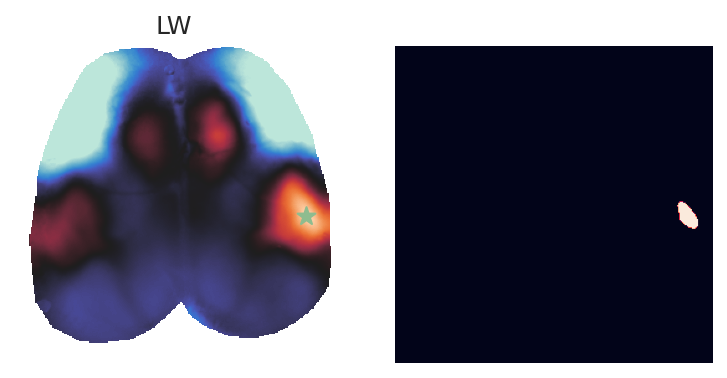

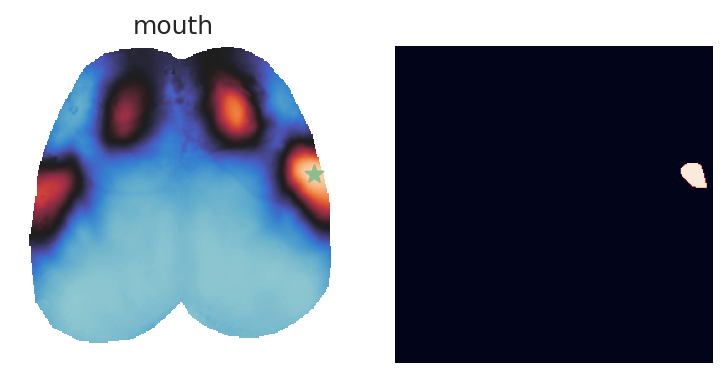

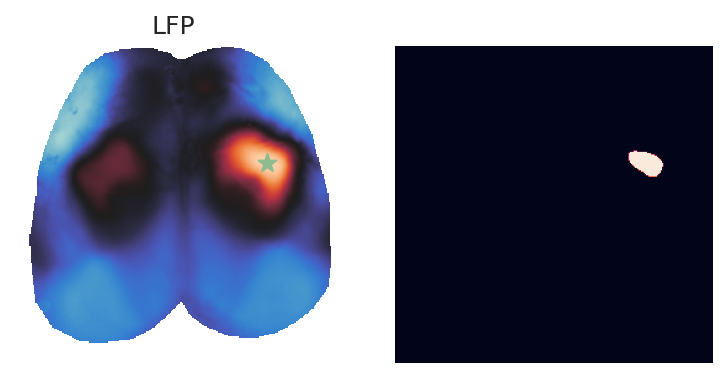

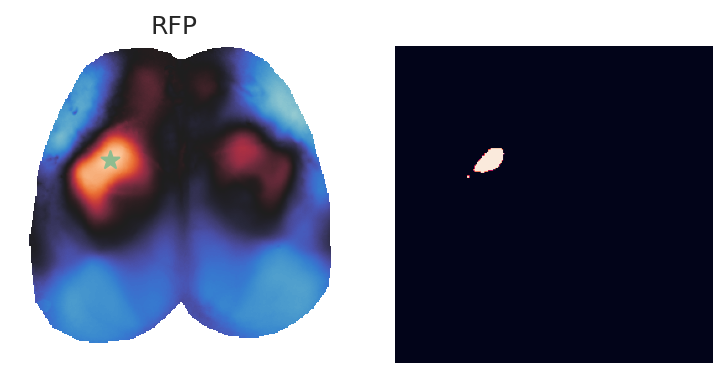

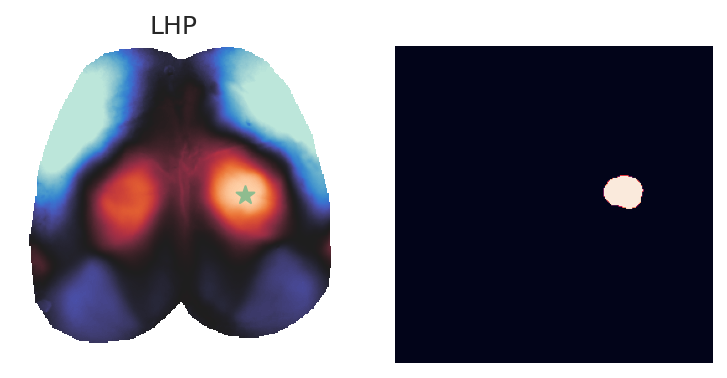

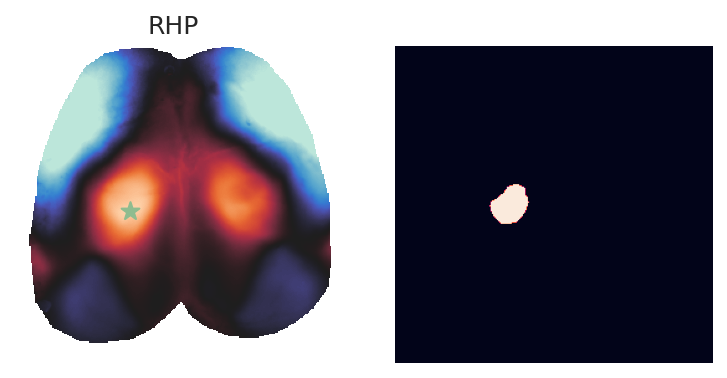

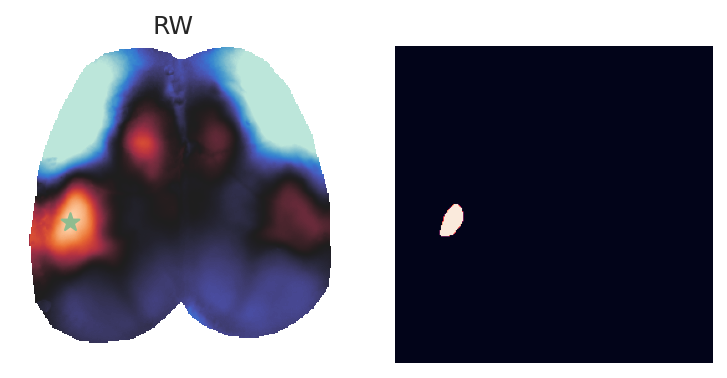

In [40]:
corr_pair_dict = {key:[] for key in brightest_ind}
for i_key,key in enumerate(brightest_ind):
    region_number=brightest_ind[key]
    corr_map  = get_region_ind(region_number,threshold=0.95,isshow=True,save_name=key)
    corr_maps_dict[key+'-sensory'] = corr_map

In [ ]:
save_all_path = analysis_root+'pub-locker/heterogeneity/all-seed/'

all_corr_maps_dict = {}
for i_key in range(500):
    corr_map = get_region_ind(i_key,threshold=0.95,isshow=False,save_name=str(i_key))
    all_corr_maps_dict[i_key] = corr_map



all_corr_maps_dict_backup={}
for i_key,key in enumerate(all_corr_maps_dict):
    all_corr_maps_dict_backup['roi_'+str(key)]=np.array(all_corr_maps_dict[key],dtype=float)


with h5py.File(save_all_path+mouse+'_all_corr_maps_dict.h5', 'w') as hf:
    for i_key,key in enumerate(all_corr_maps_dict_backup):
        hf.create_dataset(key, data=all_corr_maps_dict_backup[key])

In [25]:
fetch_path=str(PREPARES / "heterogeneity") + "/"
brightest_frontline_ind = load_model(fetch_path+'brightest_frontline_ind-'+mouse)


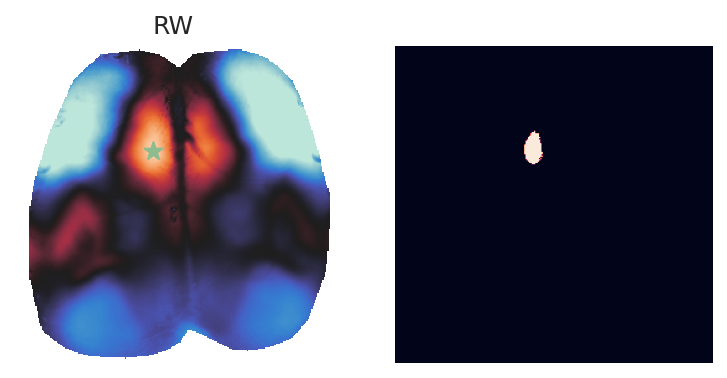

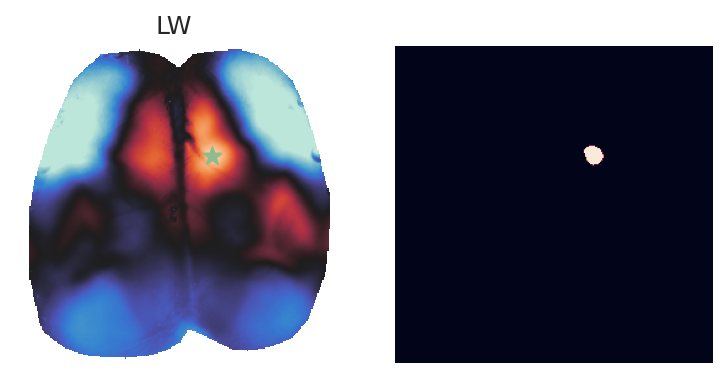

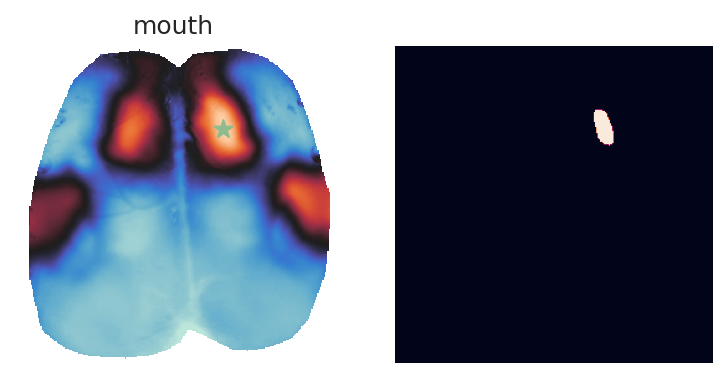

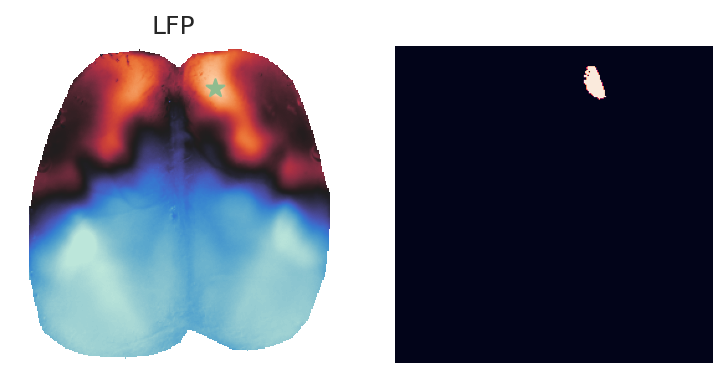

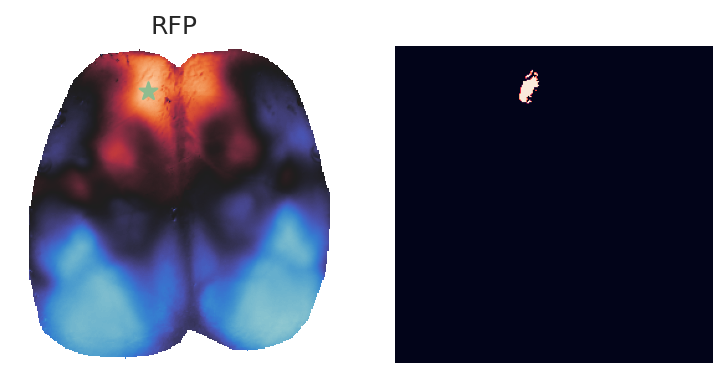

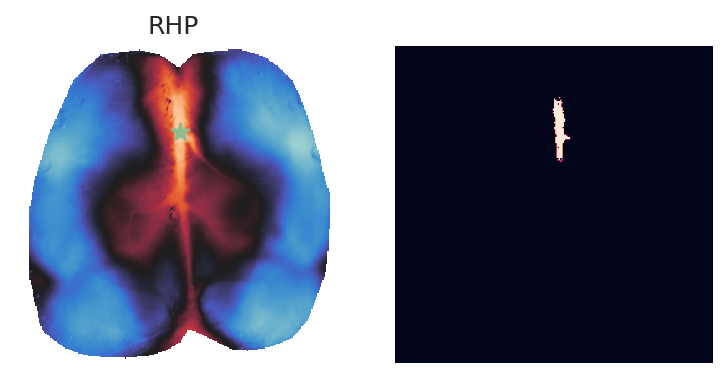

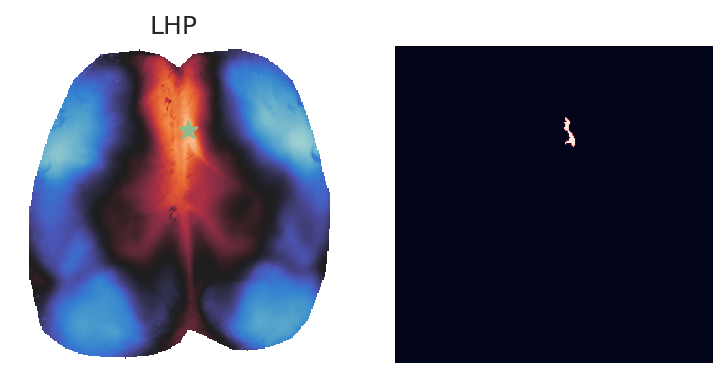

In [26]:
corr_pair_dict = {key:[] for key in brightest_frontline_ind}
for i_key,key in enumerate(brightest_frontline_ind):
    region_number=brightest_frontline_ind[key]
    corr_map = get_region_ind(region_number,threshold=0.95,isshow=True,save_name=key)
    corr_maps_dict[key+'-motor'] = corr_map

In [27]:

corr_map = get_corr_map_full(M_jrgeco,65)
corr_maps_dict['visual'] = corr_map
scipy.io.savemat(save_path+mouse+'corr_maps_dict.mat', corr_maps_dict)

In [12]:
# this is only for cm193
# fetch_path=str(PREPARES / "sensory-boop-test") + "/"
# brightest_ind = load_model(fetch_path+'brightest_ind_'+mouse)
# contours = load_model(fetch_path+'contours_'+mouse)

**sensory guessing**

cm125/6/8

In [17]:
analysis_root = '/scratch/users/wx2203/new_analysis_locker/'
fetch_path = analysis_root+'pub-locker/sensory-mapping/'
brightest_ind = load_model(fetch_path+'brightest_ind_'+mouse)
contours = load_model(fetch_path+'contours_'+mouse)



In [18]:
brightest_ind

{'RW': 445}

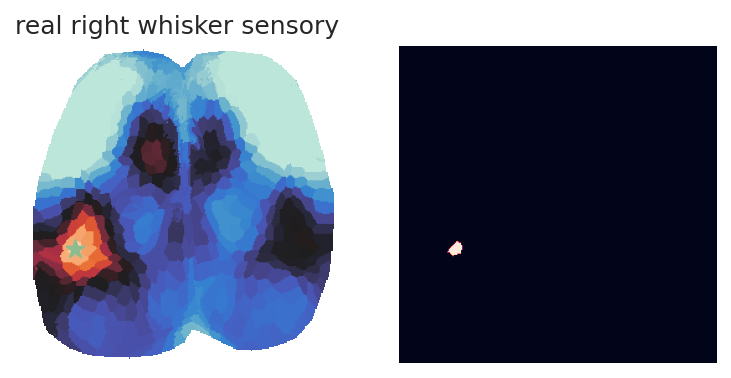

In [27]:
thr=0.95
ind_RW ,b1= get_region_ind(region_number=brightest_ind['RW'],threshold=thr,isshow=True,save_name='real right whisker sensory')
    

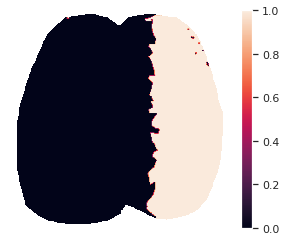

In [26]:
frontlines =node_coords[:,1]>170
show_map(frontlines,[0,1])

**find left whisker sensory**


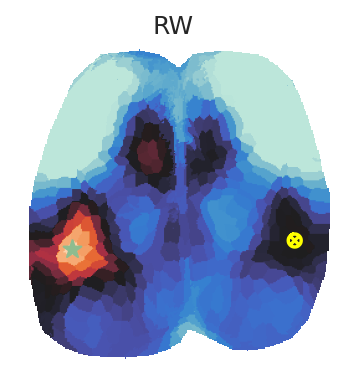

In [30]:
for i_key,key in enumerate(brightest_ind):
    region_number=brightest_ind[key]
    corr_map,corr_pair = get_corr_map(M_jrgeco,region_number)
    front_ind = np.argmax(np.multiply(frontlines,corr_pair))
    brightest_LW_ind = front_ind
    
    plt.figure(figsize=(6,3),dpi=150)
    plt.subplot(121)
    plt.title(key)
    plt.imshow(corr_map,cmap='icefire',vmin=0,vmax=1)
    plt.axis('off')
    plt.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=80, c='darkseagreen', zorder=2)
    plt.scatter(node_coords[front_ind,1], node_coords[front_ind,0], marker=r'$\bigotimes$', s=50, c='yellow', zorder=1)


In [33]:
brightest_LW_ind

39

In [38]:
inferred_brightest_ind={}
inferred_brightest_ind['LW'] = 39

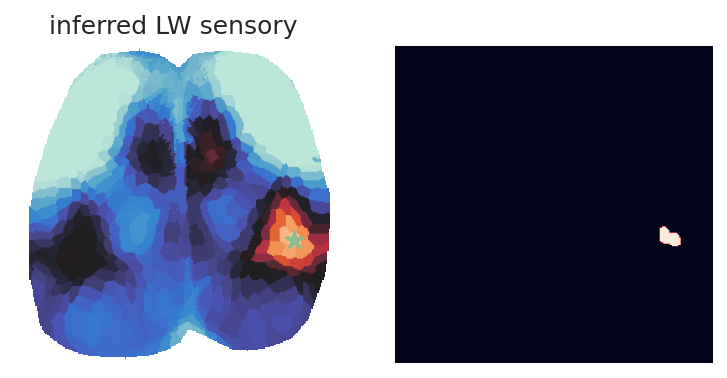

In [39]:
thr=0.95
ind_LW ,b1= get_region_ind(region_number=inferred_brightest_ind['LW'],threshold=thr,isshow=True,save_name='inferred LW sensory')

In [44]:
inferred_brightest_ind['mouth'] = 5

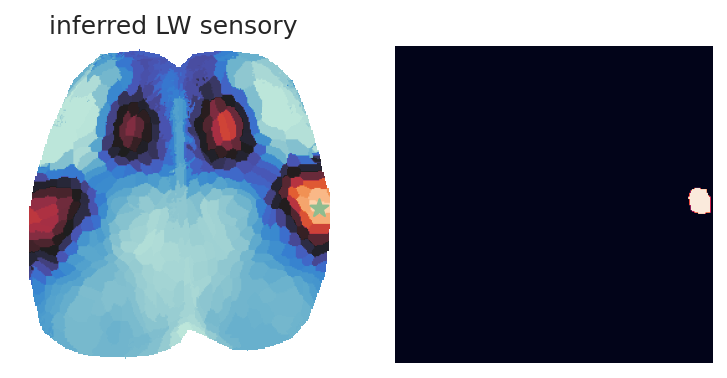

In [45]:
thr=0.95
ind_LW ,b1= get_region_ind(region_number=inferred_brightest_ind['mouth'],threshold=thr,isshow=True,save_name='inferred LW sensory')

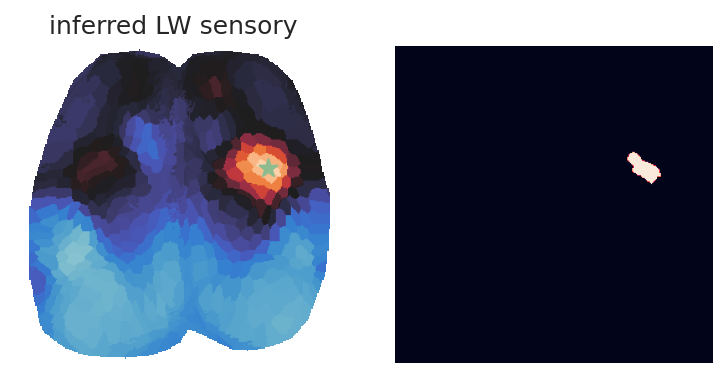

In [46]:
thr=0.95
ind_LW ,b1= get_region_ind(region_number=77,threshold=thr,isshow=True,save_name='inferred LW sensory')

In [52]:
inferred_brightest_ind['LFP'] = 77

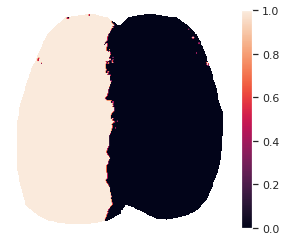

In [49]:
frontlines =node_coords[:,1]<120
show_map(frontlines,[0,1])

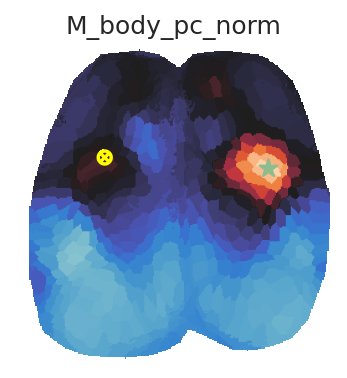

In [50]:

region_number=77
corr_map,corr_pair = get_corr_map(M_jrgeco,region_number)
front_ind = np.argmax(np.multiply(frontlines,corr_pair))
brightest_LW_ind = front_ind

plt.figure(figsize=(6,3),dpi=150)
plt.subplot(121)
plt.title(key)
plt.imshow(corr_map,cmap='icefire',vmin=0,vmax=1)
plt.axis('off')
plt.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=80, c='darkseagreen', zorder=2)
plt.scatter(node_coords[front_ind,1], node_coords[front_ind,0], marker=r'$\bigotimes$', s=50, c='yellow', zorder=1)


In [73]:
inferred_brightest_ind['RFP'] = 400

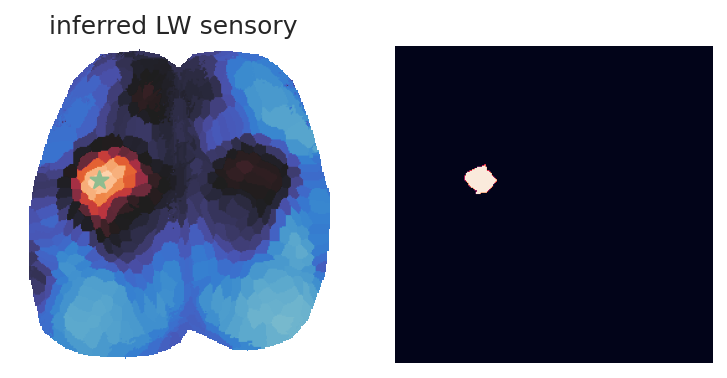

In [74]:
thr=0.95
ind_LW ,b1= get_region_ind(region_number=400,threshold=thr,isshow=True,save_name='inferred LW sensory')

In [65]:
inferred_brightest_ind['LHP'] = 117

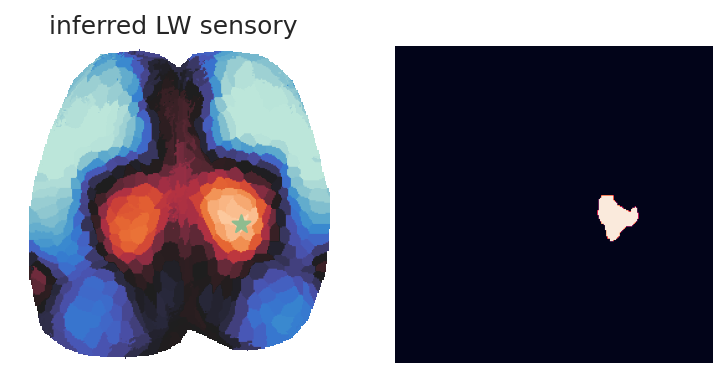

In [66]:
thr=0.95
ind_LW ,b1= get_region_ind(region_number=117,threshold=thr,isshow=True,save_name='inferred LW sensory')

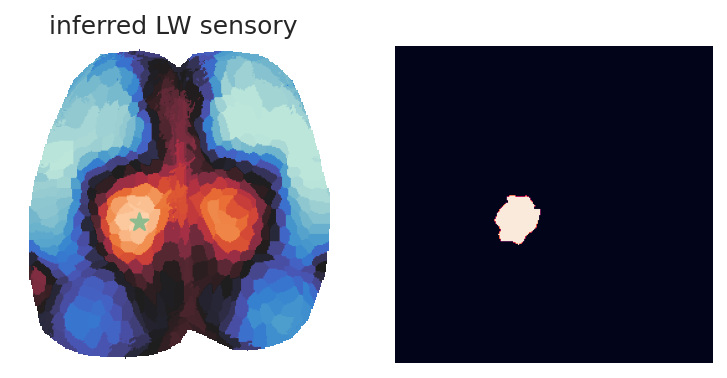

In [67]:
thr=0.95
ind_LW ,b1= get_region_ind(region_number=316,threshold=thr,isshow=True,save_name='inferred LW sensory')

In [69]:
inferred_brightest_ind['RHP'] = 316

In [75]:
inferred_brightest_ind

{'LW': 39, 'mouth': 5, 'LFP': 77, 'RFP': 400, 'RHP': 316, 'LHP': 117}

In [78]:
inferred_brightest_ind['RW'] = 445

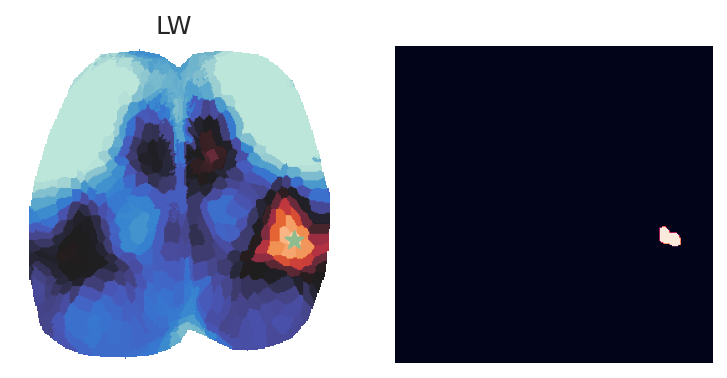

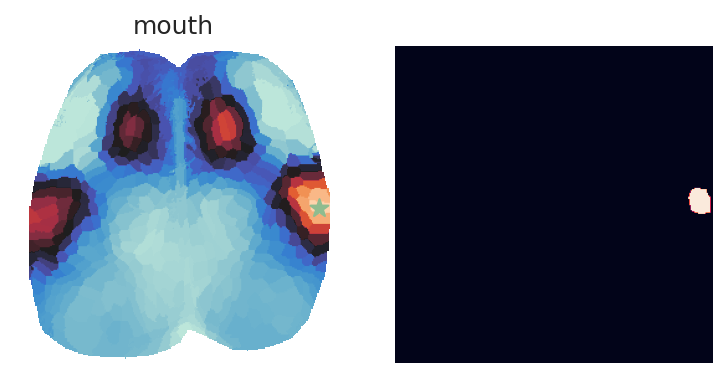

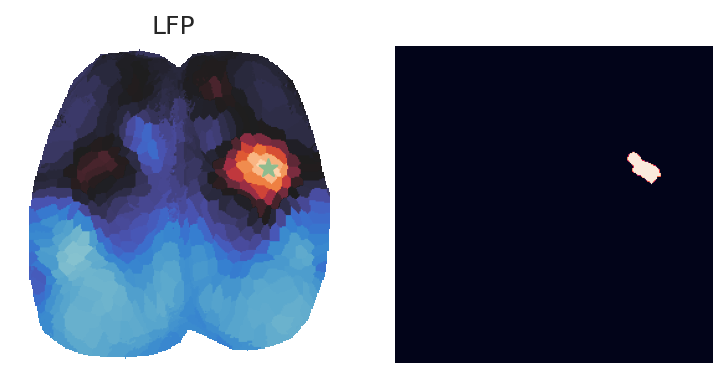

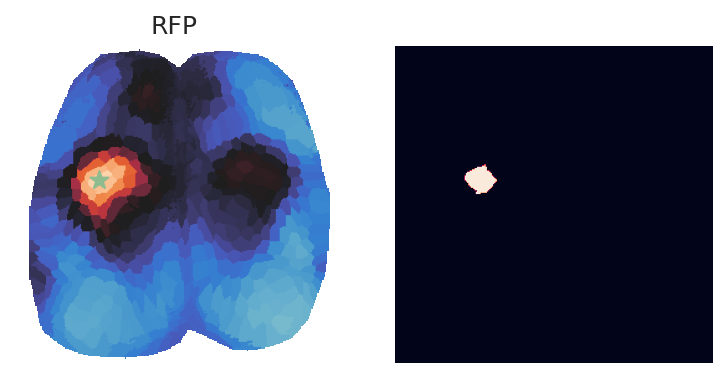

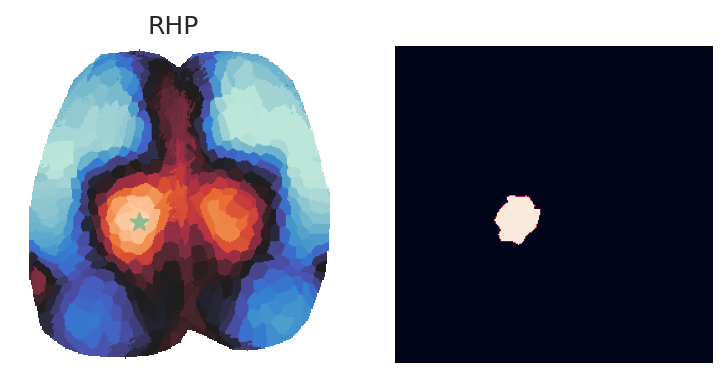

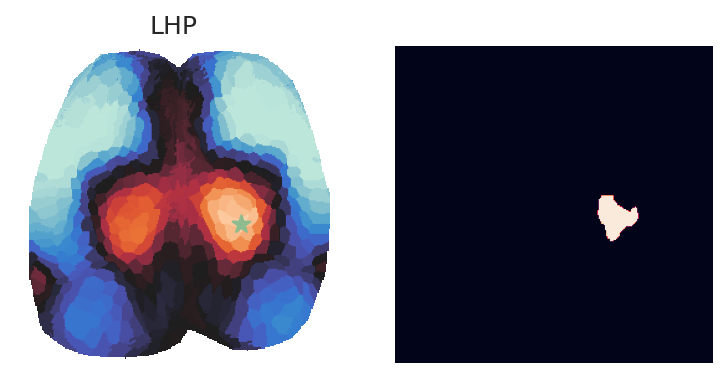

In [76]:
thr = 0.95
for i_key,key in enumerate(inferred_brightest_ind):
    exec("ind_{} ,b1= get_region_ind(region_number=inferred_brightest_ind[key],threshold=thr,isshow=True,save_name=key)".format(key))
    

# find motor region

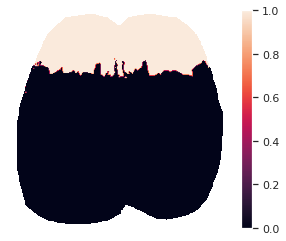

In [79]:
frontlines =node_coords[:,0]<70
show_map(frontlines,[0,1])

**left whisker and left mouth motor**


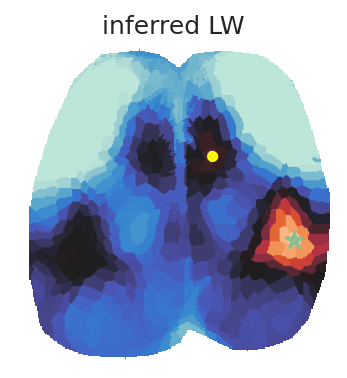

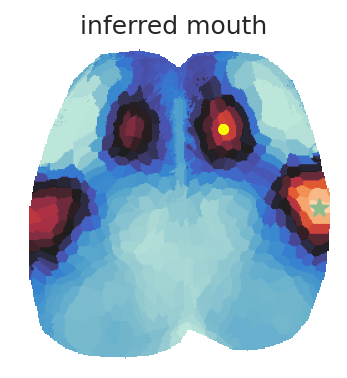

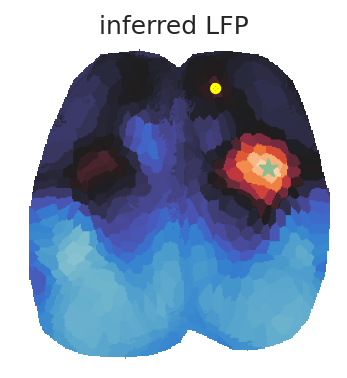

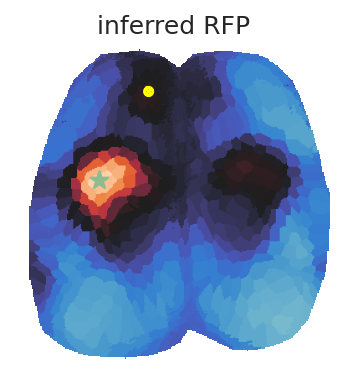

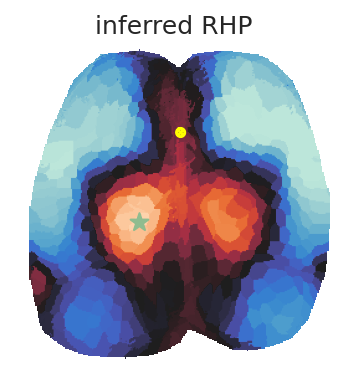

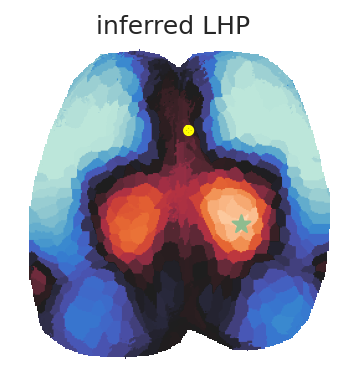

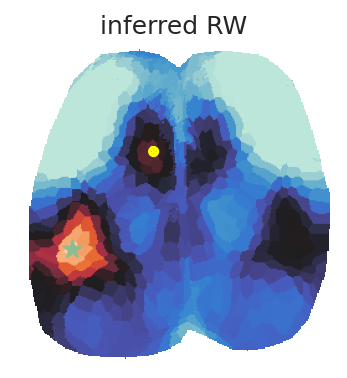

In [95]:
brightest_frontline_ind = {key:[] for key in brightest_ind}
for i_key,key in enumerate(inferred_brightest_ind):
    region_number=inferred_brightest_ind[key]
    corr_map,corr_pair = get_corr_map(M_jrgeco,region_number)
    if key=='LW' or key=='RW':
        temp_frontline = node_coords[:,0]<120
        front_ind = np.argmax(np.multiply(temp_frontline,corr_pair))
    else:
        front_ind = np.argmax(np.multiply(frontlines,corr_pair))
    brightest_frontline_ind[key] = front_ind
    
    plt.figure(figsize=(6,3),dpi=150)
    plt.subplot(121)
    plt.title('inferred '+key)
    plt.imshow(corr_map,cmap='icefire',vmin=0,vmax=1)
    plt.axis('off')
    plt.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=80, c='darkseagreen', zorder=2)
    plt.scatter(node_coords[front_ind,1], node_coords[front_ind,0], marker=r'$\bigotimes$', s=20, c='yellow', zorder=1)


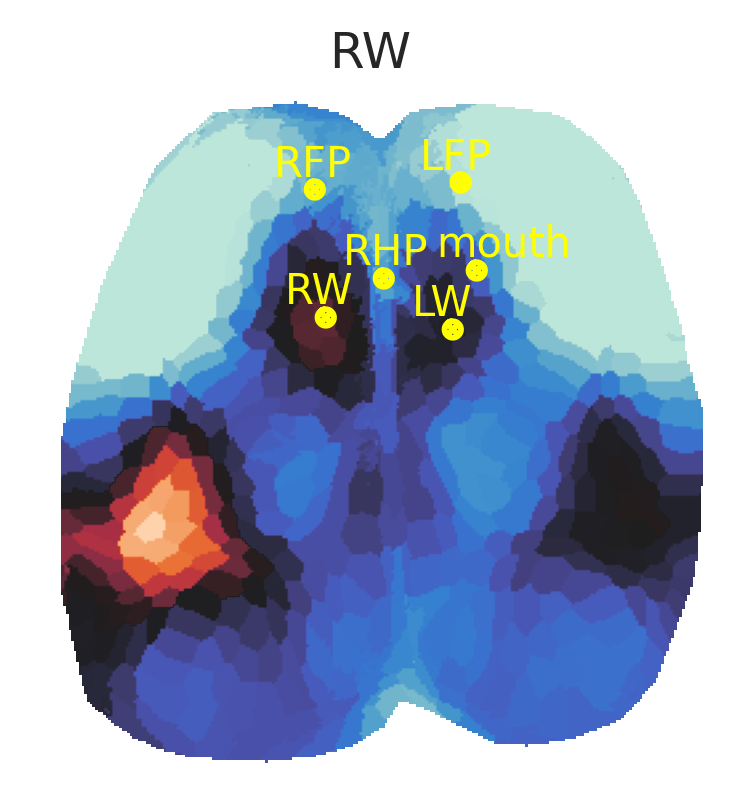

In [112]:
plt.figure(figsize=(3,3),dpi=300)
plt.title(key)
plt.imshow(corr_map,cmap='icefire',vmin=0,vmax=1)
plt.axis('off')
for i_key,key in enumerate(['LFP','RFP','mouth','RHP','LW','RW']):
    b_f_ind = brightest_frontline_ind[key]
    plt.scatter(node_coords[b_f_ind,1], node_coords[b_f_ind,0], marker=r'$\bigotimes$', s=20, c='yellow', zorder=1)
    plt.text(node_coords[b_f_ind,1]-15, node_coords[b_f_ind,0]-5,key, fontsize=10,color='yellow')


In [116]:
# for matlab
# for key in inferred_brightest_ind:
#     inferred_brightest_ind[key] = inferred_brightest_ind[key]+1
# inferred_brightest_ind

{'LW': 40,
 'mouth': 6,
 'LFP': 78,
 'RFP': 401,
 'RHP': 317,
 'LHP': 118,
 'RW': 446}

In [117]:
# for matlab
# for key in brightest_frontline_ind:
#     brightest_frontline_ind[key] = brightest_frontline_ind[key]+1
# brightest_frontline_ind

{'RW': 290,
 'LW': 171,
 'mouth': 151,
 'LFP': 165,
 'RFP': 298,
 'RHP': 235,
 'LHP': 218}

In [93]:
save_path

'/scratch/users/wx2203/new_analysis_locker/pub-locker/heterogeneity/'

In [94]:
save_model(brightest_frontline_ind,save_path+'brightest_frontline_ind-'+mouse)

In [96]:
fetch_path=str(PREPARES / "sensory-boop-test") + "/"
save_model(inferred_brightest_ind,fetch_path+'inferred_brightest_ind_'+mouse)


In [57]:
# thr = 0.95
# ind_front_ear ,b1= get_region_ind(region_number=68,threshold=thr,isshow=True,save_name='front_ear')
# ind_blob1,b2 = get_region_ind(region_number=169,threshold=thr,isshow=True,save_name='blob1')
# ind_blob2,b3 = get_region_ind(region_number=16,threshold=thr,isshow=True,save_name='blob2')
# ind_lfp,b4 = get_region_ind(region_number=95,threshold=thr,isshow=True,save_name='lfp')
# ind_lhp,b5 = get_region_ind(region_number=162,threshold=thr,isshow=True,save_name='lhp')
# ind_vis,b6 = get_region_ind(region_number=60,threshold=thr,isshow=True,save_name='vis')

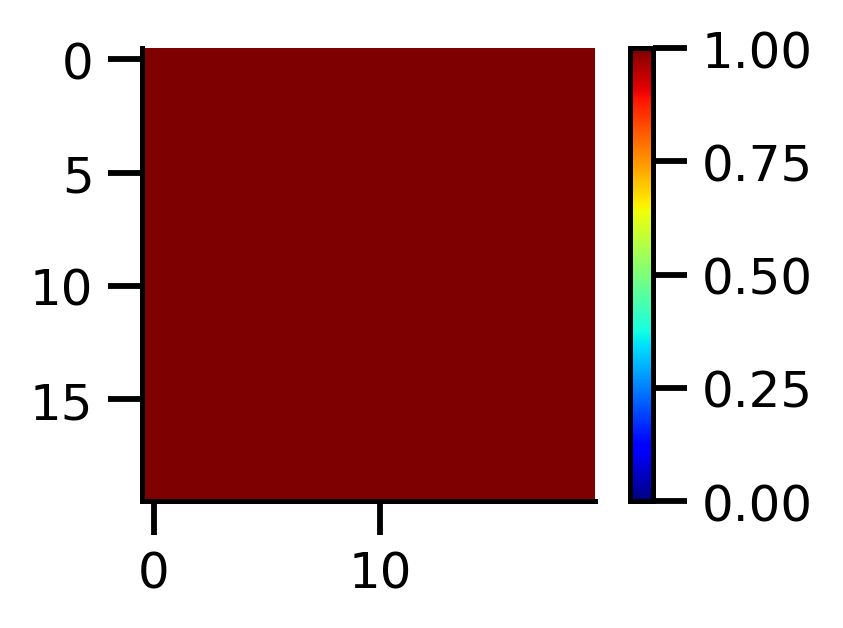

In [103]:
sns.set_style("whitegrid", {'axes.grid' : False})
with plt.style.context('default'):
    plt.figure(figsize=(3,2),dpi=300)
    plt.imshow(np.ones((20,20)).transpose(),vmin=-0,vmax=1,cmap='jet')
    plt.colorbar()
# plt.figure(figsize=(5,5))
# sns.heatmap(M_rotf.transpose(),vmin=-0,vmax=1,cmap='coolwarm')

**show example time courses**

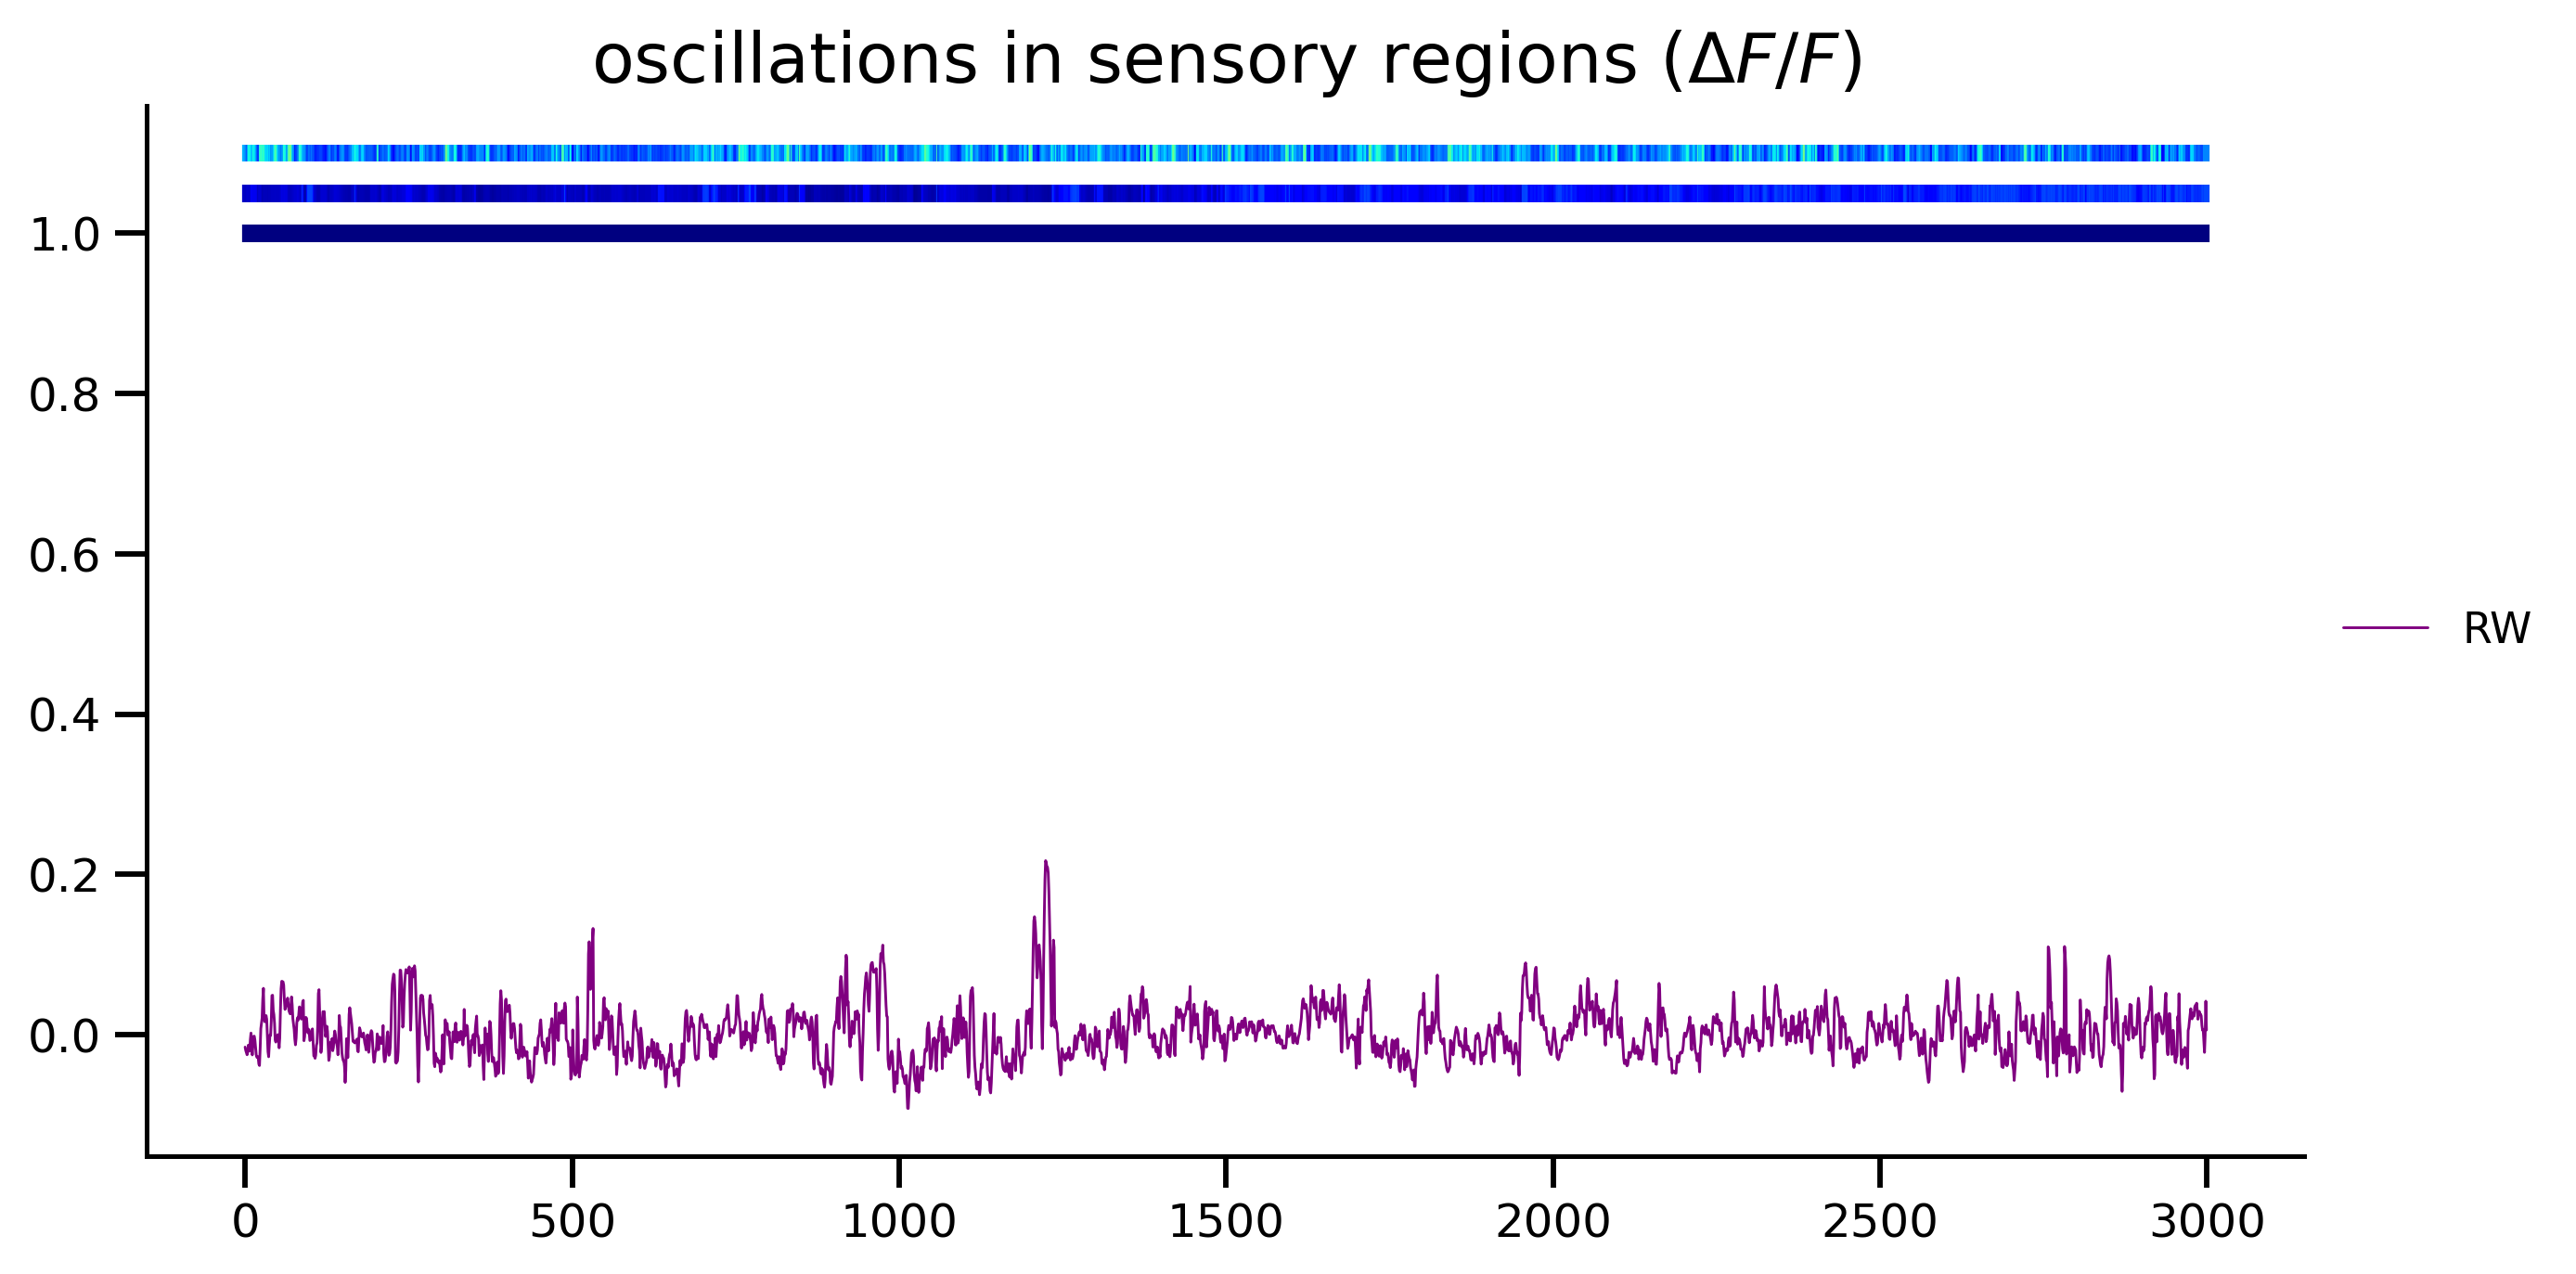

In [32]:
t_range = range(10000,13000)
colors = ['purple']+ sns.color_palette("Set2")
with plt.style.context('default'):
    plt.figure(figsize=(10,5),dpi=300)
    for i_key, key in enumerate(brightest_ind):
        plt.plot(M_jrgeco[brightest_ind[key],t_range]+0.1*i_key,color=colors[i_key],label=key,linewidth=0.7)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.title('oscillations in sensory regions ($\Delta F/F$)')
    
all_beh_gathered = ['M_whisk_vel_norm','M_LFP_vel_norm','M_body_pc_norm']
for i_key,key in enumerate(all_beh_gathered):
    exec("to_plot = {}[t_range]".format(key))
    plt.scatter(range(len(to_plot)),np.ones((len(to_plot)))*1.1-0.05*i_key,marker="|",s=20,c=to_plot,vmin=0,vmax=1,cmap='jet')

save

In [55]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model

fetch_path = str(PREPARES / "heterogeneity") + "/"
regions_list=['ind_front_ear','ind_blob1','ind_blob2','ind_lfp','ind_lhp','ind_vis']

regions_dict = {key:[] for key in regions_list}
for key in regions_list:
    exec("regions_dict[key] = {}".format(key))
save_model(regions_dict,fetch_path+mouse+'_regions_dict_095')

# regions_dict = load_model(fetch_path+mouse+'_regions_dict_095')

In [49]:
def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))

    if if_return_map ==True:
        return std_map
    else:
        plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
        plt.axis('off')
        plt.colorbar()


In [32]:
all_gathered = ['M_jrgeco','M_whisk_vel_norm','M_LFP_vel_norm','M_RFP_vel_norm']
all_gathered_dict = {key:[] for key in all_gathered}
for key in all_gathered_dict:
    exec("all_gathered_dict[key] = {}".format(key))

In [33]:
# scipy.io.savemat('/scratch/users/wx2203/new_analysis_locker/pub-locker/wheel-running/'+mouse+'_raw.mat',
#                        all_gathered_dict)

# save_model(data_joint,'/scratch/users/wx2203/new_analysis_locker/pub-locker/wheel-running/'+mouse+'_dlc_joint')

In [59]:
f = scipy.io.loadmat('/scratch/users/wx2203/new_analysis_locker/pub-locker/wheel-running/'+mouse+'_raw.mat')
M_jrgeco=f['M_jrgeco']
M_jrgeco_std=f['M_jrgeco_std']
M_whisk_vel = f['M_whisk_vel']
M_whisk_vel_norm = f['M_whisk_vel_norm']
M_LFP_vel=f['M_LFP_vel']
M_LFP_vel_norm=f['M_LFP_vel_norm']
M_RFP_vel=f['M_RFP_vel']
M_RFP_vel_norm=f['M_RFP_vel_norm']
M_day_label=np.squeeze(f['M_day_label'])
M_is_groom=f['M_is_groom']
M_y_rise_LFP=f['M_y_rise_LFP']
M_ind_onset=np.squeeze(f['M_ind_onset'])

dlc_joint = load_model('/scratch/users/wx2203/new_analysis_locker/pub-locker/wheel-running/'+mouse+'_dlc_joint')
levelnames = dlc_joint.index.get_level_values(0).drop_duplicates()
dlc_joint.index = set_level_values(dlc_joint.index, level='row_level', values=np.repeat(range(len(levelnames)), T))



In [60]:
T_PRE 


300

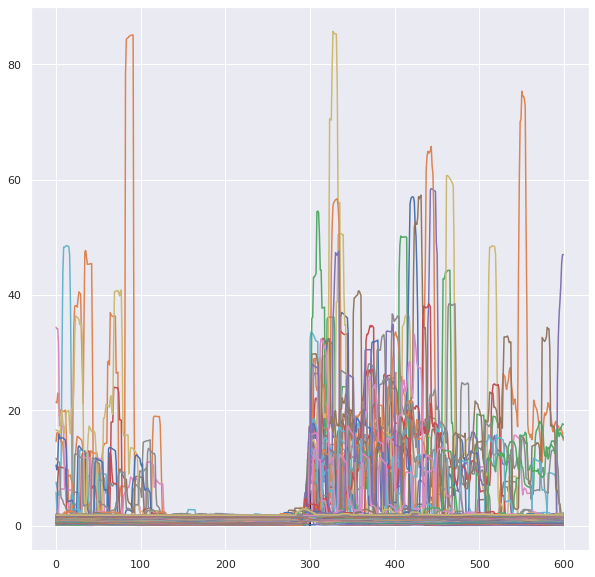

In [61]:
plt.figure(figsize=(10,10))
for i in range(M_LFP_vel_norm.shape[1]):
    plt.plot(M_LFP_vel_norm[:,i]+0.02*i)
plt.vlines(range(T_PRE,T_PRE+1),0, 6,linewidth = 2)
# plt.xlim([,680])

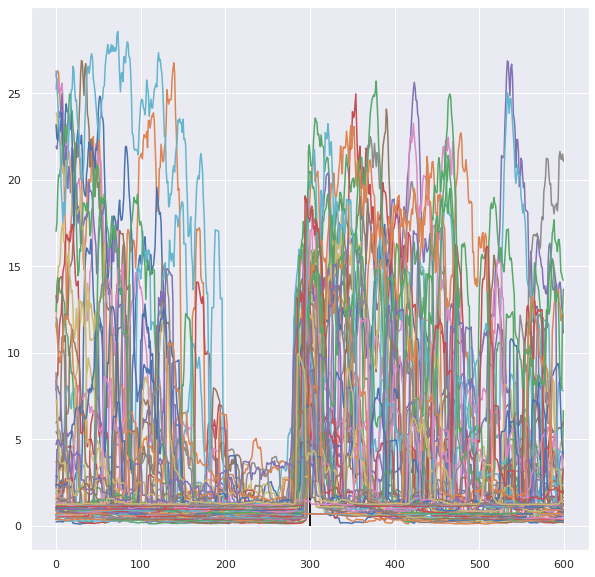

In [80]:
plt.figure(figsize=(10,10))
for i in range(M_whisk_vel_norm.shape[1]):
    plt.plot(M_whisk_vel_norm[:,i]+0.02*i)
plt.vlines(range(T_PRE,T_PRE+1),0, 6,linewidth = 2)
# plt.xlim([,680])

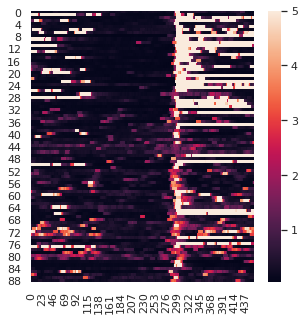

In [64]:
plt.figure(figsize=(5,5))
sns.heatmap(M_vel_norm[:455,:].T,vmax=5)

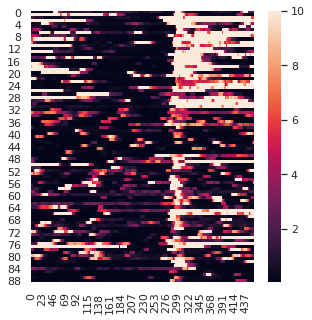

In [67]:
plt.figure(figsize=(5,5))
sns.heatmap(M_whisk_vel_norm[:455,:].T,vmax=10)

**first pass**

(59,)


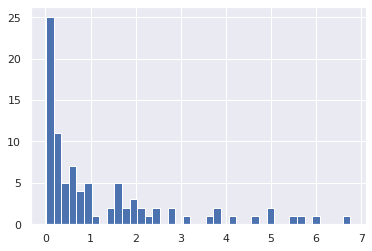

In [71]:
before_running_std = np.std(M_whisk_vel_norm[T_PRE-100:T_PRE-20,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 1.5
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)

In [72]:
print('before ',M_LFP_vel.shape)

M_day_label = M_day_label[ss_ind]
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_jrgeco_std = M_jrgeco_std[:,:,ss_ind]
M_whisk_vel = M_whisk_vel[:,ss_ind]
M_whisk_vel_norm = M_whisk_vel_norm[:,ss_ind]
M_is_groom = M_is_groom[:,ss_ind]
M_ind_onset = M_ind_onset[ss_ind]
M_y_rise_LFP = M_y_rise_LFP[:,ss_ind]
M_LFP_vel=M_LFP_vel[:,ss_ind]
M_LFP_vel_norm=M_LFP_vel_norm[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_RFP_vel_norm=M_RFP_vel_norm[:,ss_ind]

dlc_joint=dlc_joint.loc[np.squeeze(np.where(ss_ind==True))]
#reset index
levelnames = dlc_joint.index.get_level_values(0).drop_duplicates()
dlc_joint.index = set_level_values(dlc_joint.index, level='row_level', values=np.repeat(range(len(levelnames)), T))

print('after ',M_LFP_vel.shape)


before  (600, 89)
after  (600, 59)


In [81]:
# scipy.io.savemat('/scratch/users/wx2203/new_analysis_locker/pub-locker/wheel-running/'+mouse+'_filtered.mat',
#                        all_gathered_dict)
# save_model(dlc_joint,'/scratch/users/wx2203/new_analysis_locker/pub-locker/wheel-running/'+mouse+'_dlc_joint_filtered')

**second pass**

In [73]:
# before_running_std = np.std(M_RFP_vel_norm[:T_PRE_new-5,:],axis=0)
# n, bins, patches = plt.hist(before_running_std,bins=40)
# ss = 0.5
# ss_ind = before_running_std<ss
# print(np.where(ss_ind==True)[0].shape)

In [74]:
# print('before ',M_LFP_vel.shape)

# M_day_label = M_day_label[ss_ind]
# M_jrgeco = M_jrgeco[:,:,ss_ind]
# M_jrgeco_std = M_jrgeco_std[:,:,ss_ind]
# M_whisk_vel = M_whisk_vel[:,ss_ind]
# M_whisk_vel_norm = M_whisk_vel_norm[:,ss_ind]
# M_is_groom = M_is_groom[:,ss_ind]
# M_ind_onset = M_ind_onset[ss_ind]
# M_y_rise_LFP = M_y_rise_LFP[:,ss_ind]
# M_LFP_vel=M_LFP_vel[:,ss_ind]
# M_LFP_vel_norm=M_LFP_vel_norm[:,ss_ind]
# M_RFP_vel=M_RFP_vel[:,ss_ind]
# M_RFP_vel_norm=M_RFP_vel_norm[:,ss_ind]

# dlc_joint=dlc_joint.loc[np.squeeze(np.where(ss_ind==True))]
# #reset index
# levelnames = dlc_joint.index.get_level_values(0).drop_duplicates()
# dlc_joint.index = set_level_values(dlc_joint.index, level='row_level', values=np.repeat(range(len(levelnames)), T))

# print('after ',M_LFP_vel.shape)


In [75]:
# plt.figure(figsize=(10,10))
# for i in range(M_LFP_vel_norm.shape[1]):
#     plt.plot(M_LFP_vel_norm[:,i]+0.02*i)
# plt.vlines(range(running_onset,running_onset+1),0, 6,linewidth = 2)
# plt.xlim([0,280])

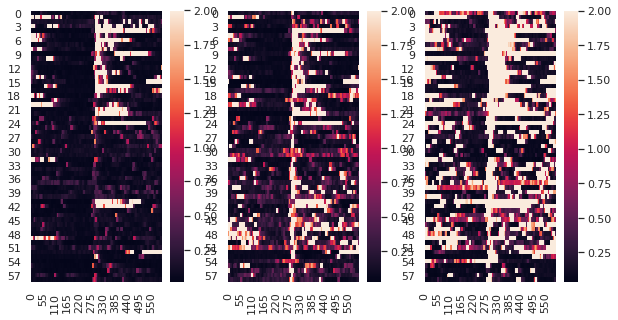

In [79]:
plt.figure(figsize=(10,5))
plt.subplot(131)
sns.heatmap(M_LFP_vel_norm[:,:].T,vmax=2)
plt.subplot(132)
sns.heatmap(M_RFP_vel_norm[:,:].T,vmax=2)
plt.subplot(133)
sns.heatmap(M_whisk_vel_norm[:,:].T,vmax=2)

**second pass**

(94,)


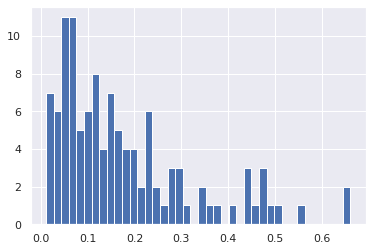

In [54]:
before_running_std = np.std(M_body_pc[T_PRE_new-40:T_PRE_new,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.3
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)

In [55]:
print('before ',M_rotf.shape)

M_rotf = M_rotf[:,ss_ind]
M_rotf_raw = M_rotf_raw[:,ss_ind]
M_face_pc = M_face_pc[:,ss_ind]
M_body_pc = M_body_pc[:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_jrgeco_std = M_jrgeco_std[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_chbt_std = M_chbt_std[:,:,ss_ind]
M_pupil_pc = M_pupil_pc[:,ss_ind]
M_whisk_vel = M_whisk_vel[:,ss_ind]
M_whisk_vel_norm = M_whisk_vel_norm[:,ss_ind]
M_nose_vel = M_nose_vel[:,ss_ind]
M_nose_vel_norm = M_nose_vel_norm[:,ss_ind]
M_pupil_p_value = M_pupil_p_value[:,ss_ind]

M_is_groom = M_is_groom[:,ss_ind]
M_y_rise_LFP_raw = M_y_rise_LFP_raw[:,ss_ind]
M_y_rise_LFP = M_y_rise_LFP[:,ss_ind]


M_LFP_vel=M_LFP_vel[:,ss_ind]
M_LFP_vel_norm=M_LFP_vel_norm[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_RFP_vel_norm=M_RFP_vel_norm[:,ss_ind]
M_pupil_pc_norm=M_pupil_pc_norm[:,ss_ind]


M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

dlc_joint=dlc_joint.loc[np.squeeze(np.where(ss_ind==True))]
#reset index
levelnames = dlc_joint.index.get_level_values(0).drop_duplicates()
dlc_joint.index = set_level_values(dlc_joint.index, level='row_level', values=np.repeat(range(len(levelnames)), T))



print('after ',M_mirrorLHP_vel_norm.shape)





before  (500, 113)
after  (500, 94)


(0.0, 280.0)

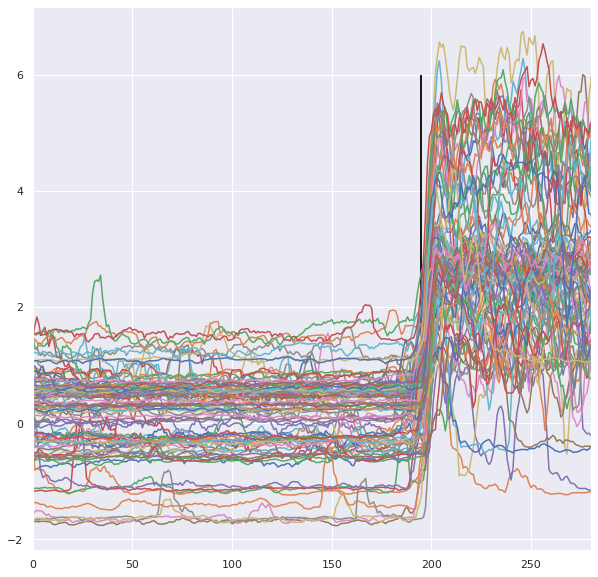

In [56]:
plt.figure(figsize=(10,10))
for i in range(M_body_pc.shape[1]):
    plt.plot(M_body_pc[:,i]+0.02*i)
plt.vlines(range(running_onset,running_onset+1),0, 6,linewidth = 2)
plt.xlim([0,280])

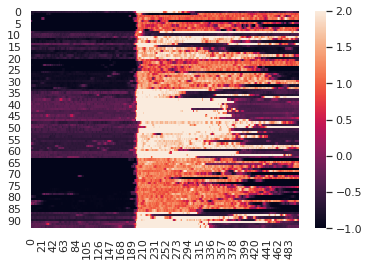

In [57]:
sns.heatmap(M_body_pc.T,vmin=-1,vmax=2)

(0.0, 320.0)

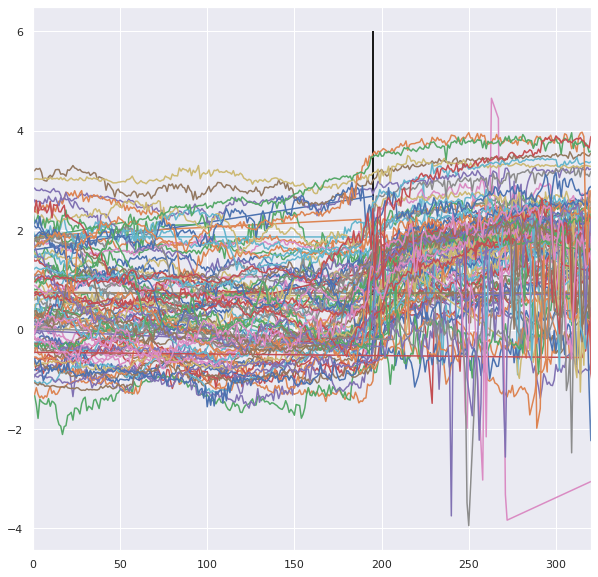

In [58]:
plt.figure(figsize=(10,10))
for i in range(M_pupil_pc.shape[1]):
    plt.plot(M_pupil_pc[:,i]+0.02*i)
plt.vlines(range(running_onset,running_onset+1),0, 6,linewidth = 2)
plt.xlim([0,320])

In [59]:
scipy.io.savemat('/home/wx2203/Weihao/analysis_locker/f2/'+mouse+'_filtered.mat',
                       {'M_jrgeco':M_jrgeco,
                        'M_jrgeco_std':M_jrgeco_std,
                        'M_chbt':M_chbt,
                        'M_chbt_std':M_chbt_std,
                        'M_rotf':M_rotf,
                        'M_rotf_raw':M_rotf_raw,
                        'M_face_pc':M_face_pc,
                        'M_body_pc':M_body_pc,
                       'M_pupil_pc':M_pupil_pc,
                        'M_whisk_vel':M_whisk_vel,
                        'M_whisk_vel_norm':M_whisk_vel_norm,
                        'M_nose_vel':M_nose_vel,
                        'M_nose_vel_norm':M_nose_vel_norm,
                        'M_pupil_p_value':M_pupil_p_value,
                        'M_LFP_vel':M_LFP_vel,
                        'M_LFP_vel_norm':M_LFP_vel_norm,
                        'M_RFP_vel':M_RFP_vel,
                        'M_RFP_vel_norm':M_RFP_vel_norm,
                        'M_pupil_pc_norm':M_pupil_pc_norm,
                       'M_day_label':M_day_label,
                        'M_is_groom':M_is_groom,
                       'M_ind_groom_onset':M_ind_groom_onset,
                       'M_y_rise_LFP':M_y_rise_LFP,
                       'M_y_rise_LFP_raw':M_y_rise_LFP_raw,
                      'M_mirrorRFP_vel':M_mirrorRFP_vel,
                       'M_mirrorRFP_vel_norm':M_mirrorRFP_vel_norm,
                        'M_mirrorLFP_vel':M_mirrorLFP_vel,
                        'M_mirrorLFP_vel_norm':M_mirrorLFP_vel_norm,
                        'M_mirrorRHP_vel':M_mirrorRHP_vel,
                        'M_mirrorRHP_vel_norm':M_mirrorRHP_vel_norm,
                        'M_mirrorLHP_vel':M_mirrorLHP_vel,
                        'M_mirrorLHP_vel_norm':M_mirrorLHP_vel_norm})



save_model(dlc_joint,'/home/wx2203/Weihao/analysis_locker/f2/'+mouse+'_dlc_joint_filtered')



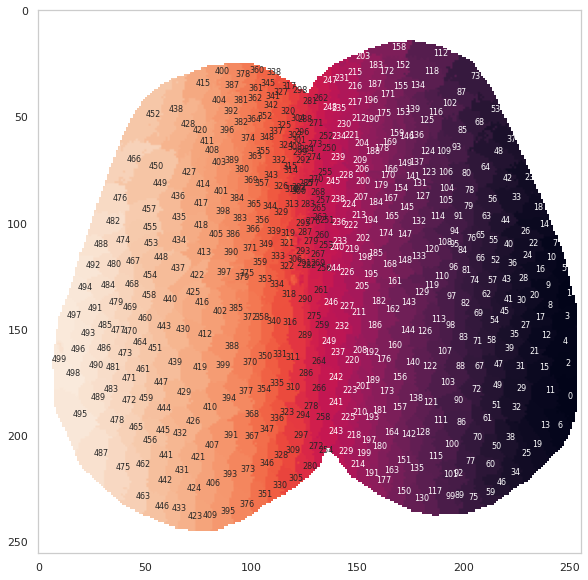

In [20]:
sns.set_style("whitegrid", {'axes.grid' : False})
plt.figure(figsize=(10,10))
plt.imshow(IDX_sorted)#,cmap='coolwarm')
#plt.clim([-50,200])
for i in range(node_coords.shape[0]):
    if i<250:
        plt.text(node_coords[i,1], node_coords[i,0], str(i),color='w',fontsize=8)
    else:
        plt.text(node_coords[i,1], node_coords[i,0], str(i),fontsize=8)